# Challenge 2: Credit Risk (default within 90 days)

## The problem in plain words
A digital bank wants a simple, practical way to spot customers who are more likely to default within the next 90 days, so that its credit team can give those customers additional review (not an automatic rejection). I have to:




## How I frame it
| Item | Definition |
|---|---|
| Unit of analysis | One **customer** (2,000 records, one row each) |
| Target | `default_90d` (1 = defaulted within 90 days, 0 = did not) |
| Features | Account, credit and repayment behaviour, plus basic profile fields |
| Output | A **risk score and risk bands** (e.g. low / medium / high) that tell the credit team *who to look at first* |
| Not the goal | Automatically approving or declining credit. The score supports a **human review decision** |

Data shows default is more common (about 1 in 4 customers), so **class imbalance is not the main difficulty**. The trade-off is between **missing a customer who goes on to default** (credit loss) and **reviewing or restricting a customer who would have repaid** (friction, lost business), and the result also needs to be **explainable and fair**, because it affects people's access to credit.

## The data (from the field guide)
| Group | Fields |
|---|---|
| Profile | `age`, `tenure_months`, `kyc_level`, `region`, `has_salary_account` |
| Income & balance | `monthly_income_pkr`, `avg_balance_pkr` |
| Account activity (30 days) | `txn_count_30d`, `debit_amt_30d_pkr`, `credit_amt_30d_pkr`, `atm_withdrawals_30d`, `card_spend_30d_pkr` |
| Repayment behaviour (6 months) | `late_payment_count_6m`, `overdraft_events_6m` |
| Credit facility | `loan_amount_pkr`, `loan_term_months`, `interest_rate_pct`, `credit_utilization_pct` |
| Engagement | `app_logins_30d`, `support_tickets_90d` |
| Identifier / outcome | `customer_id` (identifier only), `default_90d` (target) |

*Note: the outcome is historical and would not be known for a new credit decision, so it is used only to evaluate the approach.*

### Setup guide
**Setup:** Python 3.15+ with the packages in `pyproject.toml` (`uv sync`), then run all cells. The cross-validation in section 4 takes about a minute.

| Part | What it covers | |
|---|---|---|
| 1. Cleaning, 2. EDA, 3. Outliers | Is the data sound, and which customer signals separate defaulters from non-defaulters | **Core** |
| 4. Modelling | A simple risk-flag rule against logistic regression and gradient boosting; risk bands and how they behave on the records; the review-volume trade-off; what drives the score; checks that the score treats groups consistently | **Core** (the bootstrap and calibration sub-sections are *supplementary* evidence) |
| 5. Control panel | How the bank sets how strict the "needs review" line is | **Core** |
| 6. Worked examples | What the credit team sees for a flagged customer, with a correct flag, a wrong flag and a miss | **Core** |

**Recommendation:** score customers with the regularised logistic regression, group them into High / Medium / Low review bands, use the High band for human review and outreach (never an automatic decline), and let the bank choose how strict the line is.

In [40]:
import pandas as pd
import numpy as np

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Path to the dataset. Change this line if your CSV is somewhere else (see README).
CREDIT_CSV = "Interview Case Study/digital_bank_default_case_study_dataset 1.csv"
credit_raw = pd.read_csv(CREDIT_CSV)
print("Shape:", credit_raw.shape)
credit_raw.head()

Shape: (2000, 22)


,customer_id,age,tenure_months,monthly_income_pkr,avg_balance_pkr,txn_count_30d,debit_amt_30d_pkr,credit_amt_30d_pkr,atm_withdrawals_30d,card_spend_30d_pkr,late_payment_count_6m,overdraft_events_6m,loan_amount_pkr,loan_term_months,interest_rate_pct,credit_utilization_pct,has_salary_account,app_logins_30d,support_tickets_90d,kyc_level,region,default_90d
0,100000,23,106,68283,0,48,0,266017,0,45465,1,1,535680,24,19.1,9.1,1,1,1,Basic,Islamabad,0
1,100001,51,8,203564,11612,22,78831,167276,7,32994,0,0,229328,18,25.1,64.3,1,15,0,Basic,Lahore,1
2,100002,46,48,55811,168492,65,116780,331533,4,1920,0,0,50000,6,24.1,72.0,1,22,1,Enhanced,Karachi,0
3,100003,37,55,119954,23395,9,144098,39591,20,21789,0,0,931162,18,19.1,47.4,1,24,1,Basic,Lahore,0
4,100004,37,96,98976,5401,76,74157,0,7,36110,1,1,850879,24,17.4,4.8,1,26,1,Basic,Others,0


In [41]:
credit_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2000 non-null   int64  
 1   age                     2000 non-null   int64  
 2   tenure_months           2000 non-null   int64  
 3   monthly_income_pkr      2000 non-null   int64  
 4   avg_balance_pkr         2000 non-null   int64  
 5   txn_count_30d           2000 non-null   int64  
 6   debit_amt_30d_pkr       2000 non-null   int64  
 7   credit_amt_30d_pkr      2000 non-null   int64  
 8   atm_withdrawals_30d     2000 non-null   int64  
 9   card_spend_30d_pkr      2000 non-null   int64  
 10  late_payment_count_6m   2000 non-null   int64  
 11  overdraft_events_6m     2000 non-null   int64  
 12  loan_amount_pkr         2000 non-null   int64  
 13  loan_term_months        2000 non-null   int64  
 14  interest_rate_pct       2000 non-null   float64
 15

In [42]:
credit_raw.describe(percentiles=[.01, .5, .99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
customer_id,2000.0,100999.50,577.49,100000.0,100019.99,100999.5,101979.01,101999.0
age,2000.0,39.99,11.89,20.0,20.00,40.0,60.00,60.0
tenure_months,2000.0,60.78,34.49,1.0,2.99,60.0,119.00,120.0
monthly_income_pkr,2000.0,142925.37,66667.25,30000.0,30000.00,141171.0,312086.50,356196.0
avg_balance_pkr,2000.0,90086.64,76071.68,0.0,0.00,81930.5,297025.88,390864.0
txn_count_30d,2000.0,44.98,24.14,0.0,0.00,43.5,99.02,127.0
debit_amt_30d_pkr,2000.0,94675.89,72312.58,0.0,0.00,88689.0,278173.12,412066.0
credit_amt_30d_pkr,2000.0,113466.21,82082.68,0.0,0.00,107027.0,319385.36,483612.0
atm_withdrawals_30d,2000.0,6.26,4.53,0.0,0.00,6.0,18.00,22.0
card_spend_30d_pkr,2000.0,49783.24,42655.25,0.0,0.00,43593.0,158997.06,188398.0


## 1. Data cleaning & validation
Plan: check **identifiers, nulls, duplicates, data types, categories, valid ranges** against the field guide, look for **values piled up at a floor or ceiling**, and test **logical consistency between related fields**. Then decide what (if anything) to fix.

In [43]:
# Identifier, nulls, duplicates
print("Nulls:", credit_raw.isna().sum().sum())
print("Duplicate rows:", credit_raw.duplicated().sum())
print("Duplicate customer_id:", credit_raw["customer_id"].duplicated().sum())
print("customer_id dtype:", credit_raw["customer_id"].dtype, "| range", credit_raw["customer_id"].min(), "-", credit_raw["customer_id"].max())

# Categories and binary fields vs the field guide
print("\nkyc_level:", credit_raw["kyc_level"].value_counts().to_dict())
print("region:", credit_raw["region"].value_counts().to_dict())
print("Unexpected kyc:", set(credit_raw["kyc_level"]) - {"Basic", "Enhanced"})
print("Unexpected region:", set(credit_raw["region"]) - {"Karachi", "Lahore", "Islamabad", "Others"})
print("Stray whitespace:", {c: int((credit_raw[c] != credit_raw[c].str.strip()).sum()) for c in ["kyc_level", "region"]})
print("has_salary_account values:", sorted(credit_raw["has_salary_account"].unique()), "| default_90d values:", sorted(credit_raw["default_90d"].unique()))
print(f"\nDefault rate: {credit_raw['default_90d'].mean():.1%} ({credit_raw['default_90d'].sum()} of {len(credit_raw)})")

Nulls: 0
Duplicate rows: 0
Duplicate customer_id: 0
customer_id dtype: int64 | range 100000 - 101999

kyc_level: {'Basic': 1064, 'Enhanced': 936}
region: {'Karachi': 804, 'Others': 483, 'Lahore': 464, 'Islamabad': 249}
Unexpected kyc: set()
Unexpected region: set()
Stray whitespace: {'kyc_level': 0, 'region': 0}
has_salary_account values: [np.int64(0), np.int64(1)] | default_90d values: [np.int64(0), np.int64(1)]

Default rate: 25.7% (513 of 2000)


In [44]:
# Valid ranges vs the field guide
num_cols = credit_raw.select_dtypes("number").columns.drop(["customer_id"])
print("Negative values per column:", (credit_raw[num_cols] < 0).sum()[lambda s: s > 0].to_dict() or "none")
print("Utilisation outside 0-100:", ((credit_raw["credit_utilization_pct"] < 0) | (credit_raw["credit_utilization_pct"] > 100)).sum())
print("Age range:", credit_raw["age"].min(), "-", credit_raw["age"].max(), "| tenure range (months):", credit_raw["tenure_months"].min(), "-", credit_raw["tenure_months"].max())
print("Loan terms (months):", sorted(credit_raw["loan_term_months"].unique()))
print("Interest rate range (%):", credit_raw["interest_rate_pct"].min(), "-", credit_raw["interest_rate_pct"].max())
print("Income <= 0:", (credit_raw["monthly_income_pkr"] <= 0).sum())
print("\nColumns with exact zeros (count):")
print((credit_raw[num_cols] == 0).sum()[lambda s: s > 0].to_dict())

Negative values per column: none
Utilisation outside 0-100: 0
Age range: 20 - 60 | tenure range (months): 1 - 120
Loan terms (months): [np.int64(6), np.int64(12), np.int64(18), np.int64(24), np.int64(36)]
Interest rate range (%): 12.0 - 34.9
Income <= 0: 0

Columns with exact zeros (count):
{'avg_balance_pkr': 358, 'txn_count_30d': 74, 'debit_amt_30d_pkr': 299, 'credit_amt_30d_pkr': 225, 'atm_withdrawals_30d': 268, 'card_spend_30d_pkr': 379, 'late_payment_count_6m': 1394, 'overdraft_events_6m': 1507, 'credit_utilization_pct': 77, 'has_salary_account': 690, 'app_logins_30d': 168, 'support_tickets_90d': 1102, 'default_90d': 1487}


In [45]:
# Values piled up at a floor or ceiling (a sign the data was capped / censored)
checks = [("monthly_income_pkr", "min"), ("loan_amount_pkr", "min"), ("interest_rate_pct", "min"), ("age", "min"), ("age", "max"),
          ("tenure_months", "min"), ("tenure_months", "max"), ("credit_utilization_pct", "min"), ("credit_utilization_pct", "max"),
          ("avg_balance_pkr", "min"), ("txn_count_30d", "min")]
rows = []
for col, how in checks:
    v = credit_raw[col].min() if how == "min" else credit_raw[col].max()
    rows.append({"column": col, "bound": how, "value": v, "rows_at_bound": int((credit_raw[col] == v).sum()),
                 "% of rows": round((credit_raw[col] == v).mean() * 100, 1)})
display(pd.DataFrame(rows).set_index("column"))

,bound,value,rows_at_bound,% of rows
column,,,,
monthly_income_pkr,min,30000.0,118,5.9
loan_amount_pkr,min,50000.0,184,9.2
interest_rate_pct,min,12.0,15,0.8
age,min,20.0,53,2.6
age,max,60.0,49,2.4
tenure_months,min,1.0,13,0.6
tenure_months,max,120.0,19,1.0
credit_utilization_pct,min,0.0,77,3.8
credit_utilization_pct,max,100.0,6,0.3


In [46]:
# Logical consistency between related fields
c = credit_raw
checks = {
    "joined before age 18 (tenure > age - 18 years)": (c["tenure_months"] / 12 > c["age"] - 18),
    "impossible: tenure longer than age": (c["tenure_months"] / 12 > c["age"]),
    "0 transactions but money moved (debit or credit > 0)": ((c["txn_count_30d"] == 0) & ((c["debit_amt_30d_pkr"] > 0) | (c["credit_amt_30d_pkr"] > 0))),
    "transactions > 0 but 0 debit amount": ((c["txn_count_30d"] > 0) & (c["debit_amt_30d_pkr"] == 0)),
    "ATM withdrawals > total transactions": (c["atm_withdrawals_30d"] > c["txn_count_30d"]),
    "card spend > total debits": (c["card_spend_30d_pkr"] > c["debit_amt_30d_pkr"]),
    "card spend > 0 but 0 debit amount": ((c["card_spend_30d_pkr"] > 0) & (c["debit_amt_30d_pkr"] == 0)),
    "loan > 24x monthly income": (c["loan_amount_pkr"] / c["monthly_income_pkr"] > 24),
}
rows = []
for name, mask in checks.items():
    rows.append({"check": name, "rows": int(mask.sum()), "% of rows": round(mask.mean() * 100, 1),
                 "default rate in flagged rows": round(c.loc[mask, "default_90d"].mean() * 100, 1) if mask.any() else np.nan})
consistency = pd.DataFrame(rows).set_index("check")
print(f"Overall default rate: {c['default_90d'].mean():.1%}")
display(consistency)

Overall default rate: 25.7%


,rows,% of rows,default rate in flagged rows
check,,,
joined before age 18 (tenure > age - 18 years),181,9.0,21.0
impossible: tenure longer than age,0,0.0,NaN
0 transactions but money moved (debit or credit > 0),73,3.6,19.2
transactions > 0 but 0 debit amount,291,14.6,24.7
ATM withdrawals > total transactions,123,6.2,31.7
card spend > total debits,608,30.4,23.0
card spend > 0 but 0 debit amount,243,12.2,19.3
loan > 24x monthly income,81,4.0,30.9


In [47]:
# Applied the small cleaning that is actually needed. No rows are dropped and no values are changed.
credit_df = credit_raw.copy()
credit_df["customer_id"] = credit_df["customer_id"].astype(str)                 # identifier, not a number
credit_df["kyc_level"] = pd.Categorical(credit_df["kyc_level"], categories=["Basic", "Enhanced"])
credit_df["region"] = pd.Categorical(credit_df["region"], categories=["Karachi", "Lahore", "Islamabad", "Others"])

# Keep a record of the data-quality oddities (for later checks only; NOT used as model features)
credit_df["dq_activity_inconsistent"] = (
    ((credit_df["txn_count_30d"] == 0) & ((credit_df["debit_amt_30d_pkr"] > 0) | (credit_df["credit_amt_30d_pkr"] > 0)))
    | (credit_df["atm_withdrawals_30d"] > credit_df["txn_count_30d"])
    | (credit_df["card_spend_30d_pkr"] > credit_df["debit_amt_30d_pkr"])
).astype(int)
print("Rows:", len(credit_df), "| rows with any activity inconsistency:", credit_df["dq_activity_inconsistent"].sum(),
      f"({credit_df['dq_activity_inconsistent'].mean():.1%})")
print("Default rate: with inconsistency", f"{credit_df.loc[credit_df['dq_activity_inconsistent'] == 1, 'default_90d'].mean():.1%}",
      "| without", f"{credit_df.loc[credit_df['dq_activity_inconsistent'] == 0, 'default_90d'].mean():.1%}")
print(credit_df.dtypes.value_counts().to_dict())

Rows: 2000 | rows with any activity inconsistency: 702 (35.1%)
Default rate: with inconsistency 24.5% | without 26.3%
{dtype('int64'): 18, dtype('float64'): 2, <StringDtype(storage='python', na_value=nan)>: 1, CategoricalDtype(categories=['Basic', 'Enhanced'], ordered=False, categories_dtype=str): 1, CategoricalDtype(categories=['Karachi', 'Lahore', 'Islamabad', 'Others'], ordered=False, categories_dtype=str): 1}


### Cleaning findings
**What is fine**
- **No nulls, no duplicate rows or customer IDs**, no stray whitespace; `kyc_level` and `region` contain only the expected values; the binary fields are 0/1.
- **All values are inside the ranges in the field guide:** no negatives, utilisation is within 0-100, age is 20-60, tenure 1-120 months, loan terms are 6/12/18/24/36 months, interest rates 12-34.9%, income above zero.
- **Default rate is 25.7% (513 of 2,000)**, so unlike the fraud data this target is **not rare**; resampling should not be needed.

**What I changed**
- `customer_id` arrives as an integer while the field guide calls it text, so it is converted to a string (it is an identifier and will not be used as a feature).
- `kyc_level` and `region` are set as categorical columns.
- Nothing else is altered and **no rows are removed**.

**What looks odd (kept, but noted as assumptions)**
1. **Floors in the data:** 118 customers (5.9%) have income of exactly PKR 30,000 and 184 (9.2%) have a loan of exactly PKR 50,000. These pile-ups are far larger than their neighbours (only 13 customers earn between PKR 30,000 and 35,000, and only 5 have a loan between PKR 50,000 and 60,000), so the data looks **clipped at a minimum**: anything that would have been lower was set to that minimum. If so, the true value for these customers is most likely **at or below** the recorded one. (It could only be higher if the minimum is a placeholder for "unknown"; the data dictionary does not say, so this is an inference to confirm with the data owner.) A further 358 customers (17.9%) have an average balance of exactly 0; zero is a natural lower limit for a balance, so many of these accounts are probably genuinely empty rather than clipped. These values are real information, so I keep them.
2. **Joined before age 18:** 181 customers (9.0%) have a tenure longer than their adult life. This is plausible (youth accounts), and no tenure is longer than the customer's age, so I keep them.
3. **The 30-day activity fields do not always agree with each other**, which suggests they were recorded on different bases or independently:
   - **73 customers (3.6%)** show 0 transactions yet money moved,
   - **123 (6.2%)** have more ATM withdrawals than total transactions,
   - **608 (30.4%)** have card spend greater than total debits, and 291 have transactions but zero debit amount.

   In total **702 customers (35%)** trip at least one of the first three checks. Their default rate (24.5%) is close to that of the other customers (26.3%), and the individual flagged groups range from 19% to 32% against 25.7% overall, so these rows do not look like "bad" records. I therefore **keep them**, but **avoid ratio features built from these inconsistent pairs** (such as card spend / debit amount or ATM / transactions).
   
4. **Extreme leverage:** 81 customers (4.0%) have a loan of more than 24x their monthly income (default rate 30.9%, versus 25.7% overall). This is real information rather than an error, and I look at it in the outlier step.

**Next:** exploratory data analysis (who defaults?), then outlier checks, then modelling.

## 2. Exploratory data analysis
Default is common here (about 1 in 4), so the useful question for every feature is: **does the default rate move clearly above or below the 25.7% average as the feature changes?** Features whose default rate rises or falls steadily are good candidates for a score; flat ones add little.

Business questions:
1. Do **profile** fields (KYC level, region, salary account) matter?
2. Does **past repayment behaviour** (late payments, overdrafts) predict default?
3. Does the size of the **credit exposure** (utilisation, loan size, loan relative to income, rate, term) matter?
4. Does **financial capacity and relationship** (tenure, income, balance, age) matter?
5. Does day-to-day **account activity and engagement** matter?
6. Which features rank highest, and are they **independent** of each other?
7. Do signals **stack**, and how far can a **simple risk-flag count** go?

In [48]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

eda = credit_df.copy()
eda["loan_to_income"] = eda["loan_amount_pkr"] / eda["monthly_income_pkr"]     # loan size relative to monthly income
BASE = eda["default_90d"].mean()


def pct_axis(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def quantile_bins(s, q=5, fmt="{:,.0f}"):
    """Equal-sized bins with readable range labels."""
    cats = pd.qcut(s, q, duplicates="drop")
    labels = [f"{fmt.format(max(iv.left, s.min()))}-{fmt.format(iv.right)}" for iv in cats.cat.categories]
    return cats.cat.rename_categories(labels)


def rate_table(by):
    g = eda.groupby(by, observed=True)["default_90d"].agg(n="size", defaults="sum", rate="mean")
    g["lift_vs_avg"] = g["rate"] / BASE
    return g


XLABELS = {
    "kyc_level": "KYC verification level", "salary_acct": "Is salary paid into the account?", "region": "Region",
    "late_6m": "Late payments in the last 6 months", "overdraft_6m": "Overdraft events in the last 6 months",
    "tickets_90d": "Support tickets in the last 90 days",
    "credit_utilization_pct_q": "Share of available credit used (%)",
    "loan_to_income_q": "Loan size compared with monthly income (times)",
    "loan_amount_pkr_q": "Loan amount (PKR)", "interest_rate_pct_q": "Interest rate (%)",
    "loan_term_months": "Loan term (months)",
    "tenure_months_q": "Time with the bank (months)", "monthly_income_pkr_q": "Monthly income (PKR)",
    "avg_balance_pkr_q": "Average account balance (PKR)", "age_q": "Age (years)",
    "atm_withdrawals_30d_q": "ATM withdrawals in 30 days", "txn_count_30d_q": "Transactions in 30 days",
    "card_spend_30d_pkr_q": "Card spend in 30 days (PKR)", "app_logins_30d_q": "App logins in 30 days",
    "debit_amt_30d_pkr_q": "Money going out in 30 days (PKR)", "credit_amt_30d_pkr_q": "Money coming in over 30 days (PKR)",
    "n_flags": "Number of risk flags",
}
YLABEL_RATE = "Default rate (% of customers)"


def rate_bar(ax, by, title, labels=None, rotate=0, xlabel=None):
    g = rate_table(by)
    x = np.arange(len(g))
    ax.bar(x, g["rate"], color=BLUE, width=0.6)
    ax.axhline(BASE, color=INK2, ls="--", lw=1)
    ax.text(len(g) - 0.5, BASE, f" avg {BASE:.1%}", va="bottom", ha="right", color=INK2, fontsize=8)
    for xi, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(xi, r, f"{r:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(labels if labels is not None else [str(i) for i in g.index], rotation=rotate, ha="right" if rotate else "center")
    ax.set_ylim(0, g["rate"].max() * 1.3)
    pct_axis(ax); ax.set_title(title)
    ax.set_xlabel(xlabel or XLABELS.get(by, str(by).replace("_", " ").capitalize()))
    ax.set_ylabel(YLABEL_RATE)
    return g


# Capped / binned versions of fields for charting
eda["late_6m"] = eda["late_payment_count_6m"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
eda["overdraft_6m"] = eda["overdraft_events_6m"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
eda["tickets_90d"] = eda["support_tickets_90d"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
for col, q, fmt in [("credit_utilization_pct", 5, "{:.0f}"), ("loan_to_income", 5, "{:.1f}"), ("loan_amount_pkr", 5, "{:,.0f}"),
                    ("interest_rate_pct", 5, "{:.1f}"), ("tenure_months", 5, "{:.0f}"), ("monthly_income_pkr", 5, "{:,.0f}"),
                    ("avg_balance_pkr", 5, "{:,.0f}"), ("age", 5, "{:.0f}"), ("atm_withdrawals_30d", 5, "{:.0f}"),
                    ("txn_count_30d", 5, "{:.0f}"), ("card_spend_30d_pkr", 5, "{:,.0f}"), ("app_logins_30d", 5, "{:.0f}"),
                    ("debit_amt_30d_pkr", 5, "{:,.0f}"), ("credit_amt_30d_pkr", 5, "{:,.0f}")]:
    eda[col + "_q"] = quantile_bins(eda[col], q, fmt)

# Plain-language names for the features, used on the driver charts
FEATURE_NAMES = {
    "late_payments_6m": "Late payments (6 months)", "late_payment_count_6m": "Late payments (6 months)",
    "overdrafts_6m": "Overdrafts (6 months)", "overdraft_events_6m": "Overdrafts (6 months)",
    "credit_utilization_pct": "Credit utilisation", "log_loan_to_income": "Loan compared with income", "loan_to_income": "Loan compared with income",
    "log_income": "Monthly income", "monthly_income_pkr": "Monthly income", "log_avg_balance": "Average balance", "avg_balance_pkr": "Average balance",
    "tenure_months": "Time with the bank", "atm_withdrawals_30d": "ATM withdrawals (30 days)", "support_tickets_90d": "Support tickets (90 days)",
    "interest_rate_pct": "Interest rate", "loan_term_months": "Loan term", "has_salary_account": "Salary account", "kyc_enhanced": "Enhanced KYC",
    "app_logins_30d": "App logins (30 days)", "txn_count_30d": "Transactions (30 days)", "log_card_spend": "Card spend (30 days)",
    "card_spend_30d_pkr": "Card spend (30 days)", "debit_amt_30d_pkr": "Money going out (30 days)", "credit_amt_30d_pkr": "Money coming in (30 days)",
    "loan_amount_pkr": "Loan amount", "age": "Age",
}

def nice_names(names):
    return [FEATURE_NAMES.get(n, n.replace("_", " ")) for n in names]


### Q1. Do profile fields matter? (KYC level, salary account, region)

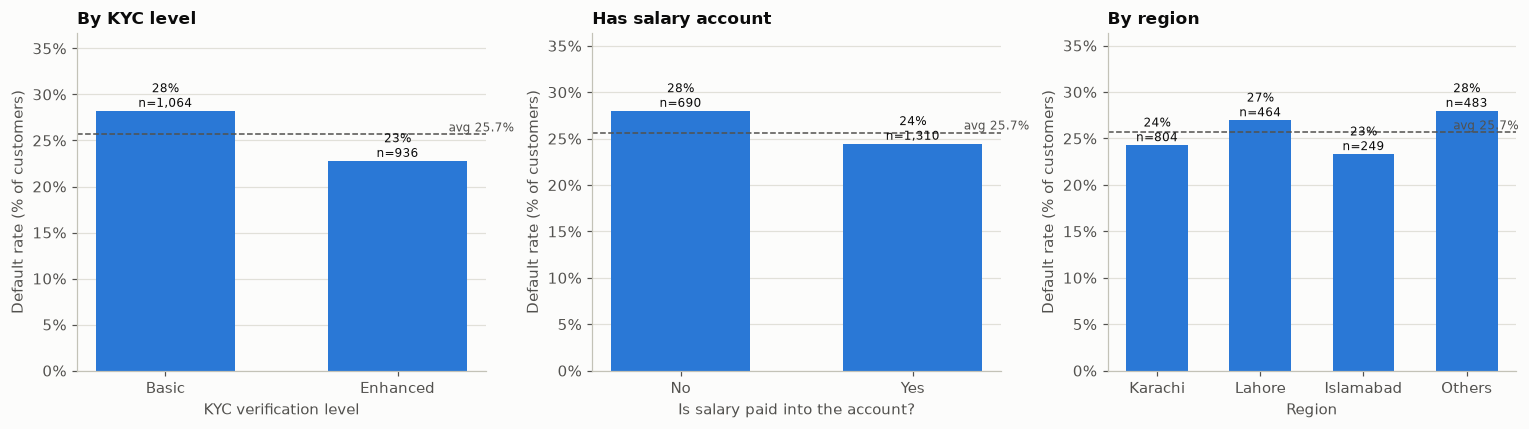

n  defaults   rate  lift_vs_avg
kyc_level salary_acct                                   
Basic     No           360       110  0.306        1.191
          Yes          704       190  0.270        1.052
Enhanced  No           330        83  0.252        0.981
          Yes          606       130  0.215        0.836

In [49]:
eda["salary_acct"] = eda["has_salary_account"].map({0: "No", 1: "Yes"})
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rate_bar(axes[0], "kyc_level", "By KYC level")
rate_bar(axes[1], "salary_acct", "Has salary account")
rate_bar(axes[2], "region", "By region")
plt.tight_layout(); plt.show()
display(rate_table(["kyc_level", "salary_acct"]).round(3))

**Reading:** Profile fields move default only modestly. Basic KYC customers default at 28.2% vs 22.8% for Enhanced, customers without a salary account at 28.0% vs 24.4% with one, and regions range from 23.3% (Islamabad) to 28.0% ("Others"). All are within roughly ±10% of the average, so these are **weak signals on their own**. A note for responsible use: **region is a geographic proxy** that can encode unintended bias, so I would be cautious about relying on it.

### Q2. Does past repayment behaviour predict default? (late payments, overdrafts)

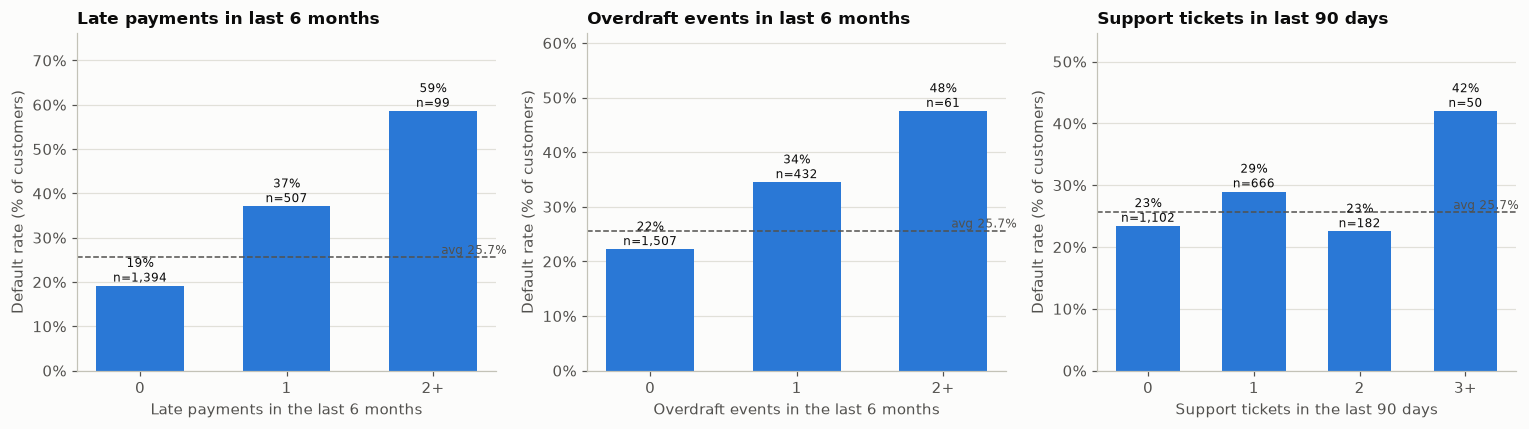

,n,defaults,rate,lift_vs_avg
late_6m,,,,
0,1394,267,0.192,0.747
1,507,188,0.371,1.446
2+,99,58,0.586,2.284


,n,defaults,rate,lift_vs_avg
overdraft_6m,,,,
0,1507,335,0.222,0.867
1,432,149,0.345,1.345
2+,61,29,0.475,1.853


In [50]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rate_bar(axes[0], "late_6m", "Late payments in last 6 months")
rate_bar(axes[1], "overdraft_6m", "Overdraft events in last 6 months")
rate_bar(axes[2], "tickets_90d", "Support tickets in last 90 days")
plt.tight_layout(); plt.show()
display(rate_table("late_6m").round(3)); display(rate_table("overdraft_6m").round(3))

**Reading:** **Past repayment behaviour is the clearest signal.**
- **Late payments:** 19.2% default with none, **37.1% with one** and about **58% with two or more** (about 3x the no-late rate). 1,394 customers (70%) have none, so this cleanly isolates a risky minority (about 30%).
- **Overdrafts:** 22.2% with none, 34.5% with one and about 47% with two or more.
- **Support tickets** show only a weak, uneven pattern (small counts at 3+), so I would not read much into them.

This is also the most intuitive signal for a credit team: customers who already struggle to pay on time are more likely to default.

### Q3. Does the size of the credit exposure matter? (utilisation, loan size, loan-to-income, rate, term)

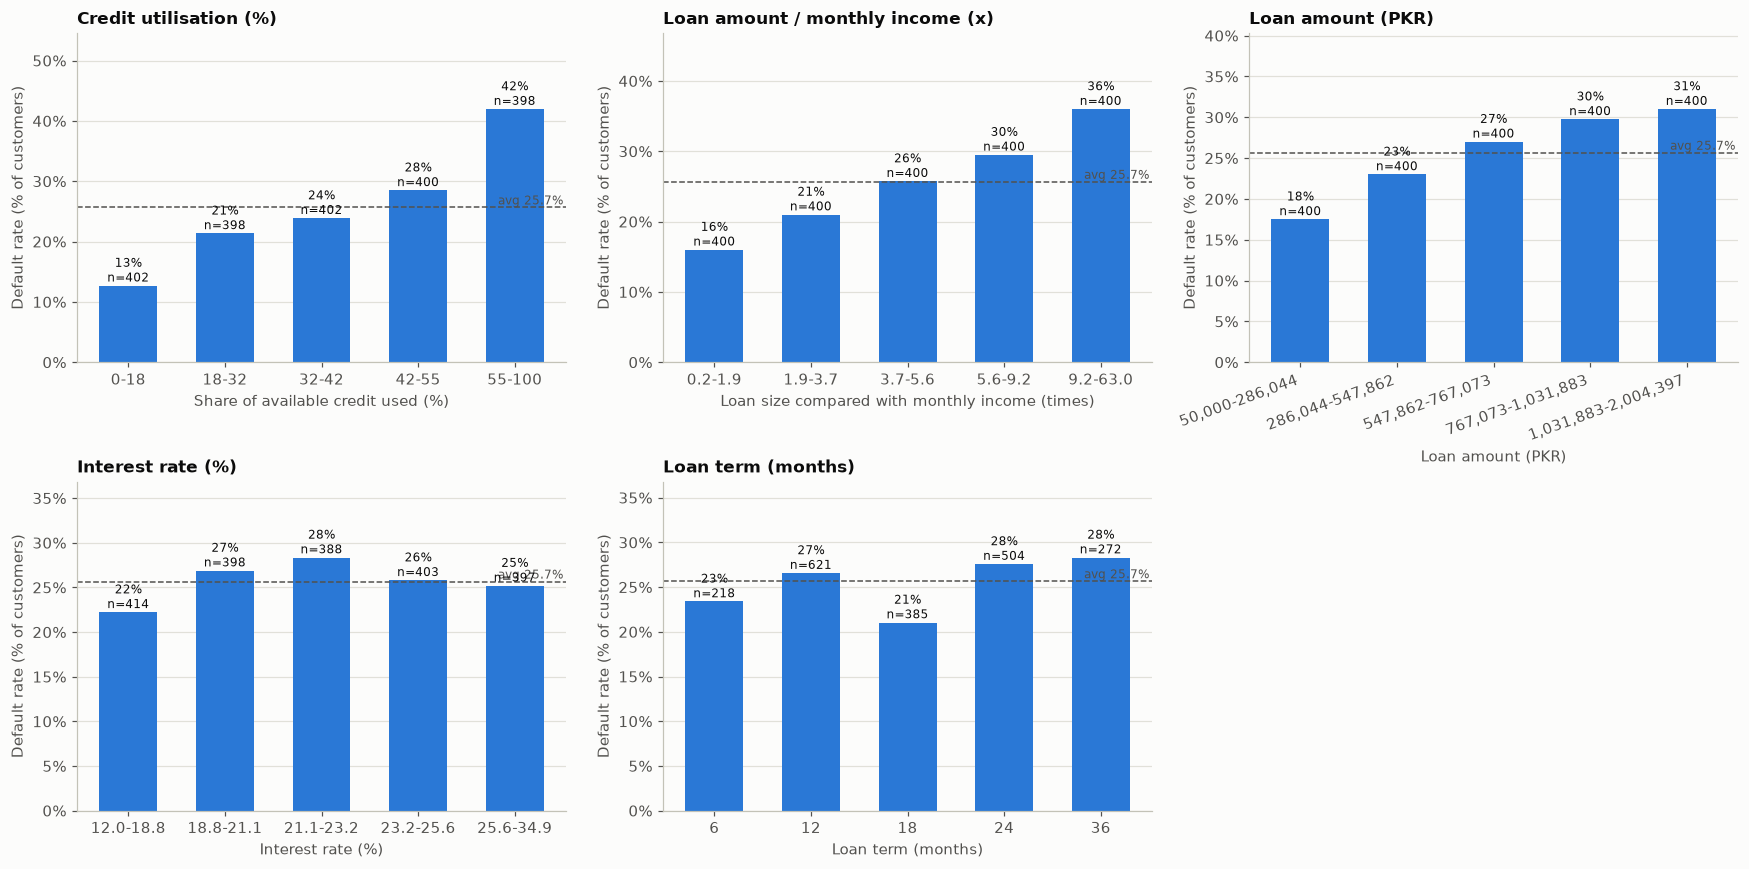

In [51]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rate_bar(axes[0, 0], "credit_utilization_pct_q", "Credit utilisation (%)")
rate_bar(axes[0, 1], "loan_to_income_q", "Loan amount / monthly income (x)")
rate_bar(axes[0, 2], "loan_amount_pkr_q", "Loan amount (PKR)", rotate=20)
rate_bar(axes[1, 0], "interest_rate_pct_q", "Interest rate (%)")
rate_bar(axes[1, 1], "loan_term_months", "Loan term (months)")
axes[1, 2].axis("off")
plt.tight_layout(); plt.show()

**Reading:**
- **Credit utilisation is a strong signal:** default rises steadily from **12.7%** (lowest 20% of utilisation) to **42.0%** (highest 20%), a 3.3x spread. Customers using most of their available credit are most stretched.
- **Loan relative to income is also strong:** from **16.0%** (lowest fifth) to **36.0%** (highest fifth). The ratio is a better measure of affordability than loan size alone (loan amount spans 17.5% to 31.0%), although the two are correlated.
- **Interest rate and loan term show no clear pattern.** Rates peak in the middle bands (not monotonic) and terms show no trend, so they add little. Note the field guide describes the rate as being "as named in the source dataset", so I would not read it as a risk-based price.

### Q4. Does financial capacity and relationship matter? (tenure, income, balance, age)

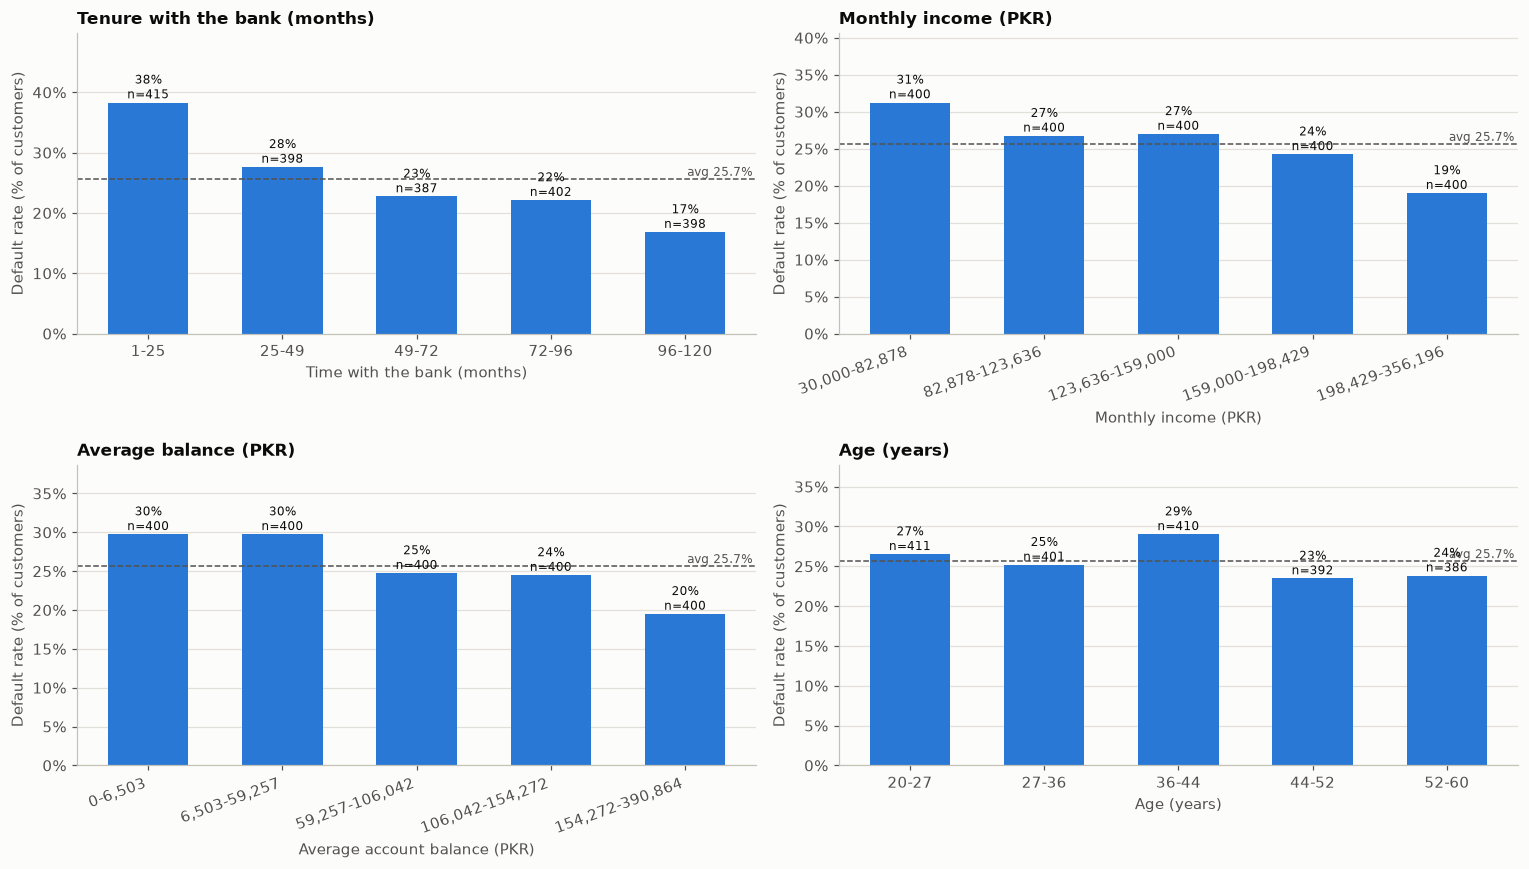

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
rate_bar(axes[0, 0], "tenure_months_q", "Tenure with the bank (months)")
rate_bar(axes[0, 1], "monthly_income_pkr_q", "Monthly income (PKR)", rotate=20)
rate_bar(axes[1, 0], "avg_balance_pkr_q", "Average balance (PKR)", rotate=20)
rate_bar(axes[1, 1], "age_q", "Age (years)")
plt.tight_layout(); plt.show()

**Reading:**
- **Tenure:** newer customers default far more often: **38.3%** with 25 months or less vs **16.8%** with 96+ months (a 2.3x spread). Customers with a long history at the bank are more reliable.
- **Income and balance:** default falls steadily as income rises (31.2% to 19.0%) and as the average balance rises (29.8% to 19.5%). The effects are moderate. About 18% of customers have a zero average balance (a floor value, see the cleaning notes).
- **Age shows no clear pattern** (23.5% to 29.0%, non-monotonic), which is helpful: age is a sensitive attribute that we would rather not rely on.

### Q5. Does account activity and engagement matter?

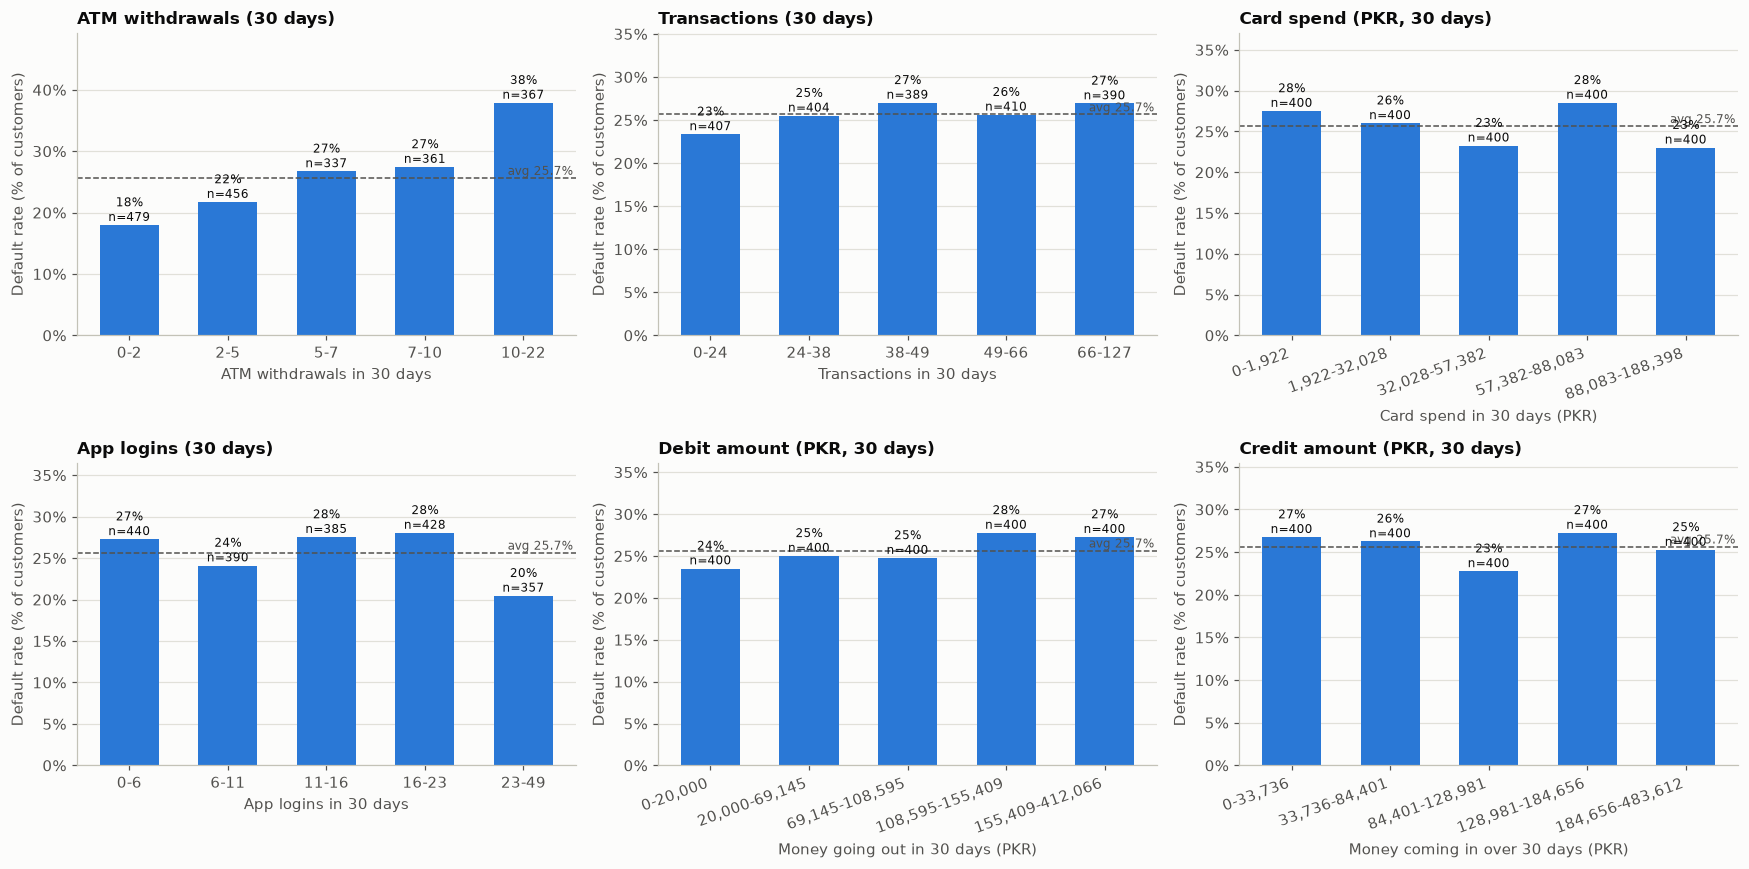

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rate_bar(axes[0, 0], "atm_withdrawals_30d_q", "ATM withdrawals (30 days)")
rate_bar(axes[0, 1], "txn_count_30d_q", "Transactions (30 days)")
rate_bar(axes[0, 2], "card_spend_30d_pkr_q", "Card spend (PKR, 30 days)", rotate=20)
rate_bar(axes[1, 0], "app_logins_30d_q", "App logins (30 days)")
rate_bar(axes[1, 1], "debit_amt_30d_pkr_q", "Debit amount (PKR, 30 days)", rotate=20)
rate_bar(axes[1, 2], "credit_amt_30d_pkr_q", "Credit amount (PKR, 30 days)", rotate=20)
plt.tight_layout(); plt.show()

**Reading:** Most activity measures are **flat**: transaction count, card spend, app logins, and debit / credit amounts all stay within about 20-29% (close to the 25.7% average, with no steady trend). The exception is **ATM withdrawals**: default rises from **18.0%** (2 or fewer) to **37.9%** (more than 10), a plausible sign of cash dependence. Given the data-quality caveats on these activity fields (see cleaning), I would give them less weight than the repayment and exposure measures.

### Q6. Which features rank highest, and are they independent?

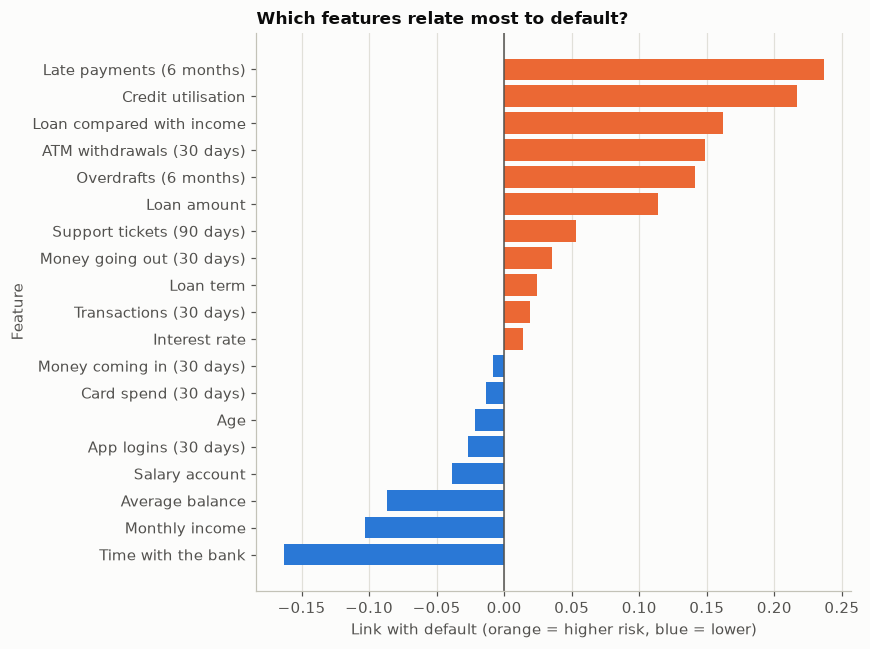

,late_payment_count_6m,overdraft_events_6m,credit_utilization_pct,atm_withdrawals_30d,loan_to_income,tenure_months
late_payment_count_6m,1.00,0.02,-0.01,-0.00,-0.01,0.00
overdraft_events_6m,0.02,1.00,0.02,0.02,-0.01,0.00
credit_utilization_pct,-0.01,0.02,1.00,0.05,0.00,0.02
atm_withdrawals_30d,-0.00,0.02,0.05,1.00,-0.01,0.02
loan_to_income,-0.01,-0.01,0.00,-0.01,1.00,-0.04
tenure_months,0.00,0.00,0.02,0.02,-0.04,1.00


Highly related pairs among all numeric features (|rho| > 0.4):
[('monthly_income_pkr', 'loan_to_income', np.float64(-0.55)), ('loan_amount_pkr', 'loan_to_income', np.float64(0.77))]


In [54]:
num = eda.select_dtypes("number").drop(columns=["default_90d", "dq_activity_inconsistent"])
spearman = num.apply(lambda s: s.corr(eda["default_90d"], method="spearman")).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(nice_names(spearman.index), spearman.values, color=[ORANGE if v > 0 else BLUE for v in spearman.values])
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Link with default (orange = higher risk, blue = lower)"); ax.set_ylabel("Feature")
ax.set_title("Which features relate most to default?")
plt.tight_layout(); plt.show()

# Are the strongest drivers independent of each other? (if so, they carry separate information and stack up)
drivers = ["late_payment_count_6m", "overdraft_events_6m", "credit_utilization_pct", "atm_withdrawals_30d", "loan_to_income", "tenure_months"]
display(eda[drivers].corr(method="spearman").round(2))
print("Highly related pairs among all numeric features (|rho| > 0.4):")
cm = num.corr(method="spearman")
print([(a, b, round(cm.loc[a, b], 2)) for i, a in enumerate(cm.columns) for b in cm.columns[i + 1:] if abs(cm.loc[a, b]) > 0.4])

**Reading:**
- **Top drivers (highest correlation with default):** late payments (0.24), credit utilisation (0.22), loan-to-income (0.16), ATM withdrawals (0.15), overdrafts (0.14), and on the protective side, tenure (-0.16), income (-0.10) and balance (-0.09). Everything else is close to zero.
- **The key drivers are nearly independent of each other** (|correlation| below about 0.1 among late payments, overdrafts, utilisation, ATM withdrawals), so each carries *separate* information, which is why signals should add up when combined.
- **Overlap to be careful about:** loan amount and loan-to-income are strongly related (0.77), and income and loan-to-income are related (-0.55). Because the ratio is built from them, including all three in a linear model would duplicate information, so I will prefer the ratio.

### Q7. Do signals stack? (interaction and a simple risk-flag count)

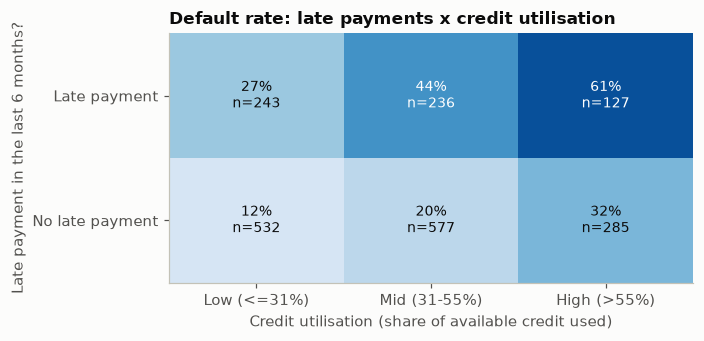

In [55]:
# Interaction: late payments x credit utilisation
eda["util_band"] = pd.cut(eda["credit_utilization_pct"], [-1, 31, 55, 100], labels=["Low (<=31%)", "Mid (31-55%)", "High (>55%)"])
eda["any_late"] = np.where(eda["late_payment_count_6m"] >= 1, "Late payment", "No late payment")
heat = eda.pivot_table(index="any_late", columns="util_band", values="default_90d", aggfunc="mean", observed=True)
cnt = eda.pivot_table(index="any_late", columns="util_band", values="default_90d", aggfunc="size", observed=True)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
im = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=0.7, aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns); ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.0%}\nn={cnt.values[i, j]}", ha="center", va="center", fontsize=9,
                color="white" if heat.values[i, j] > 0.4 else INK)
ax.grid(False); ax.set_xlabel("Credit utilisation (share of available credit used)"); ax.set_ylabel("Late payment in the last 6 months?")
ax.set_title("Default rate: late payments x credit utilisation")
plt.tight_layout(); plt.show()

Share of customers with each flag: {'late_payment': 0.303, 'overdraft': 0.246, 'high_utilisation': 0.206, 'high_loan_to_income': 0.206, 'short_tenure': 0.208, 'heavy_atm_use': 0.184}


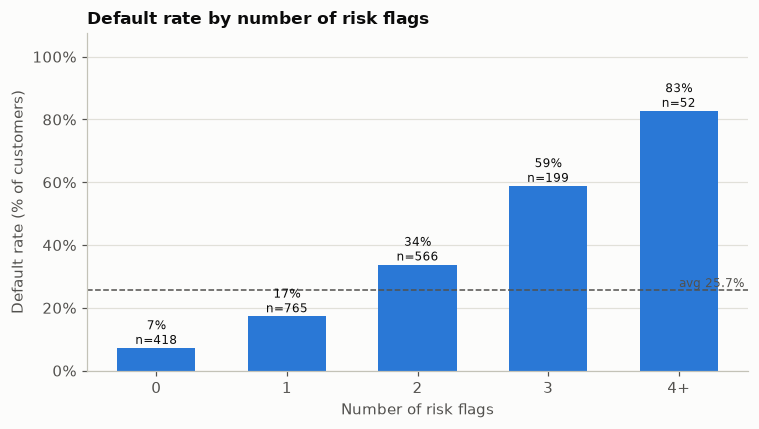

,customers flagged,% of customers,default rate in flagged,defaults captured
flag if >= k signals,,,,
1,1582,0.791,0.305,0.942
2,817,0.408,0.430,0.684
3,251,0.126,0.637,0.312
4,52,0.026,0.827,0.084


In [56]:
# Simple risk-flag count (thresholds picked from the charts above, so results are optimistic on this same data)
flags = pd.DataFrame({
    "late_payment": eda["late_payment_count_6m"] >= 1,
    "overdraft": eda["overdraft_events_6m"] >= 1,
    "high_utilisation": eda["credit_utilization_pct"] > 55,
    "high_loan_to_income": eda["loan_to_income"] > 9,
    "short_tenure": eda["tenure_months"] <= 25,
    "heavy_atm_use": eda["atm_withdrawals_30d"] > 10,
}).astype(int)
eda["n_flags"] = flags.sum(axis=1).clip(upper=4).map({0: "0", 1: "1", 2: "2", 3: "3", 4: "4+"})
print("Share of customers with each flag:", flags.mean().round(3).to_dict())

fig, ax = plt.subplots(figsize=(7, 4))
rate_bar(ax, "n_flags", "Default rate by number of risk flags")
ax.set_xlabel("Number of risk flags")
plt.tight_layout(); plt.show()

total_def = eda["default_90d"].sum(); rows = []
nf = flags.sum(axis=1)
for k in range(1, 5):
    m = nf >= k
    rows.append({"flag if >= k signals": k, "customers flagged": int(m.sum()), "% of customers": m.mean(),
                 "default rate in flagged": eda.loc[m, "default_90d"].mean(), "defaults captured": eda.loc[m, "default_90d"].sum() / total_def})
display(pd.DataFrame(rows).set_index("flag if >= k signals").round(3))

**Reading:**
- **Signals reinforce each other.** A customer with a late payment *and* high utilisation defaults **61%** of the time, vs **12%** for someone with neither. Each adds risk on top of the other.
- **A simple count of six risk flags separates customers very well:** default rises from **7%** with no flags to **17%** (1 flag), **34%** (2), **59%** (3) and **about 83%** (4+). The average is 26%, so the riskiest group is about 3x average and the safest about a quarter of it.
- **Practical cut-off:** flagging customers with 2 or more flags selects **41%** of customers, who contain **68% of all defaults** (default rate 43%). Flagging 3 or more selects 12.6% of customers with a 64% default rate, catching about 31% of defaults.


### EDA summary
| Question | Answer |
|---|---|
| Profile (KYC, region, salary account) | **Weak** (within about +/-10% of the average); region is a geographic proxy, so use with care |
| Repayment behaviour | **Strongest:** late payments (19% to 58% default), overdrafts (22% to 47%) |
| Credit exposure | **Strong:** utilisation (13% to 42%), loan-to-income (16% to 36%). Interest rate and term: no pattern |
| Financial capacity and relationship | **Moderate:** tenure (38% down to 17%), income, balance. Age: no pattern |
| Activity and engagement | **Mostly flat**, except heavy ATM use (18% to 38%) |
| Independence | Key drivers are nearly uncorrelated, so they **stack**; loan amount, income and loan-to-income overlap |
| Simple flag count | 7% to 83% default across 0 to 4+ flags |

**Implications for modelling**
1. A **lightweight, explainable model** looks well suited: the signals are clear, monotonic and independent. **Logistic regression** (and a transparent points-based scorecard) should work well, with a tree-based model as a cross-check.
2. Use **loan-to-income** instead of loan amount and income separately, and cap counts such as late payments at 2+.
3. Default is common (26%), so **no resampling**; use stratified splits and look at AUC, PR-AUC, calibration and the default rate per risk band.
4. **Responsible use:** avoided sensitive or proxy attributes (age, region) in the score

## 3. Outlier analysis
Questions for each numeric column:
1. How many customers are statistical outliers (IQR rule: beyond 1.5 x IQR from the quartiles)?
2. Are they **data errors** or **real behaviour**?
3. Do outliers **default more or less** than other customers, i.e. do they carry signal?

Money-type columns are skewed, so the IQR rule is applied on a **log10 scale** for income, loan amount and loan-to-income; other columns are used as they are. Columns where most values are 0 (IQR = 0), such as overdrafts, are handled with a simple business cut-off instead.

In [57]:
specs = [("age", False), ("tenure_months", False), ("monthly_income_pkr", True), ("avg_balance_pkr", False),
         ("txn_count_30d", False), ("debit_amt_30d_pkr", False), ("credit_amt_30d_pkr", False), ("atm_withdrawals_30d", False),
         ("card_spend_30d_pkr", False), ("late_payment_count_6m", False), ("loan_amount_pkr", True), ("loan_term_months", False),
         ("interest_rate_pct", False), ("credit_utilization_pct", False), ("app_logins_30d", False), ("loan_to_income", True)]
rows, masks = [], {}
for col, use_log in specs:
    s = np.log10(eda[col]) if use_log else eda[col].astype(float)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (s < lo) | (s > hi)
    masks[col] = m
    rows.append({"column": col, "low_outliers": int((s < lo).sum()), "high_outliers": int((s > hi).sum()),
                 "outlier_%": round(m.mean() * 100, 1),
                 "default_rate_outliers_%": round(eda.loc[m, "default_90d"].mean() * 100, 1) if m.any() else np.nan,
                 "default_rate_normal_%": round(eda.loc[~m, "default_90d"].mean() * 100, 1)})
outlier_summary = pd.DataFrame(rows).set_index("column")
display(outlier_summary)

# Columns where most values are 0 (IQR = 0): use a business cut-off instead
print("Business cut-offs (IQR is 0 for these):")
for col, cut in [("overdraft_events_6m", 3), ("support_tickets_90d", 3), ("late_payment_count_6m", 3)]:
    m = eda[col] >= cut
    print(f"  {col} >= {cut}: {m.sum()} customers, default rate {eda.loc[m, 'default_90d'].mean():.1%} vs {eda.loc[~m, 'default_90d'].mean():.1%} otherwise")

,low_outliers,high_outliers,outlier_%,default_rate_outliers_%,default_rate_normal_%
column,,,,,
age,0,0,0.0,NaN,25.6
tenure_months,0,0,0.0,NaN,25.6
monthly_income_pkr,128,0,6.4,38.3,24.8
avg_balance_pkr,0,10,0.5,10.0,25.7
txn_count_30d,0,5,0.2,40.0,25.6
debit_amt_30d_pkr,0,12,0.6,16.7,25.7
credit_amt_30d_pkr,0,8,0.4,62.5,25.5
atm_withdrawals_30d,0,15,0.8,46.7,25.5
card_spend_30d_pkr,0,3,0.2,0.0,25.7


Business cut-offs (IQR is 0 for these):
  overdraft_events_6m >= 3: 4 customers, default rate 50.0% vs 25.6% otherwise
  support_tickets_90d >= 3: 50 customers, default rate 42.0% vs 25.2% otherwise
  late_payment_count_6m >= 3: 9 customers, default rate 66.7% vs 25.5% otherwise


C:\Users\mohib\AppData\Local\Temp\ipykernel_25768\4039953080.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["No default", "Default"],
C:\Users\mohib\AppData\Local\Temp\ipykernel_25768\4039953080.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["No default", "Default"],
C:\Users\mohib\AppData\Local\Temp\ipykernel_25768\4039953080.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["No default", "Default"],
C:\User

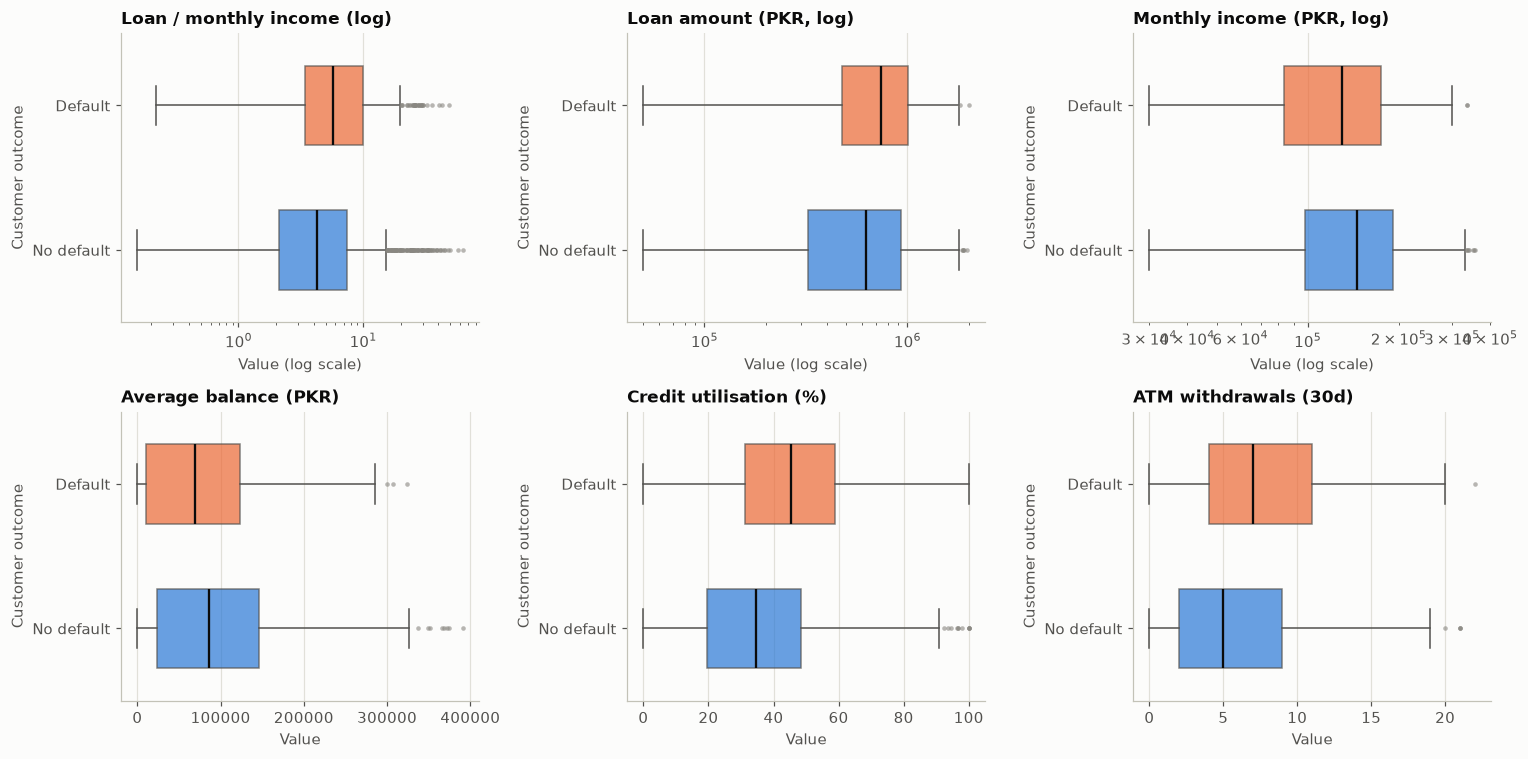

In [58]:
# Boxplots of the most relevant columns, split by outcome (outlier points shown as dots)
cols = [("loan_to_income", True, "Loan / monthly income (log)"), ("loan_amount_pkr", True, "Loan amount (PKR, log)"),
        ("monthly_income_pkr", True, "Monthly income (PKR, log)"), ("avg_balance_pkr", False, "Average balance (PKR)"),
        ("credit_utilization_pct", False, "Credit utilisation (%)"), ("atm_withdrawals_30d", False, "ATM withdrawals (30d)")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, use_log, title) in zip(axes.ravel(), cols):
    data = [eda.loc[eda["default_90d"] == 0, col], eda.loc[eda["default_90d"] == 1, col]]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["No default", "Default"],
                    flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.6),
                    medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, color in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(color); patch.set_alpha(0.7); patch.set_edgecolor(INK2)
    if use_log:
        ax.set_xscale("log")
    ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID); ax.set_title(title)
    ax.set_xlabel("Value (log scale)" if use_log else "Value"); ax.set_ylabel("Customer outcome")
plt.tight_layout(); plt.show()

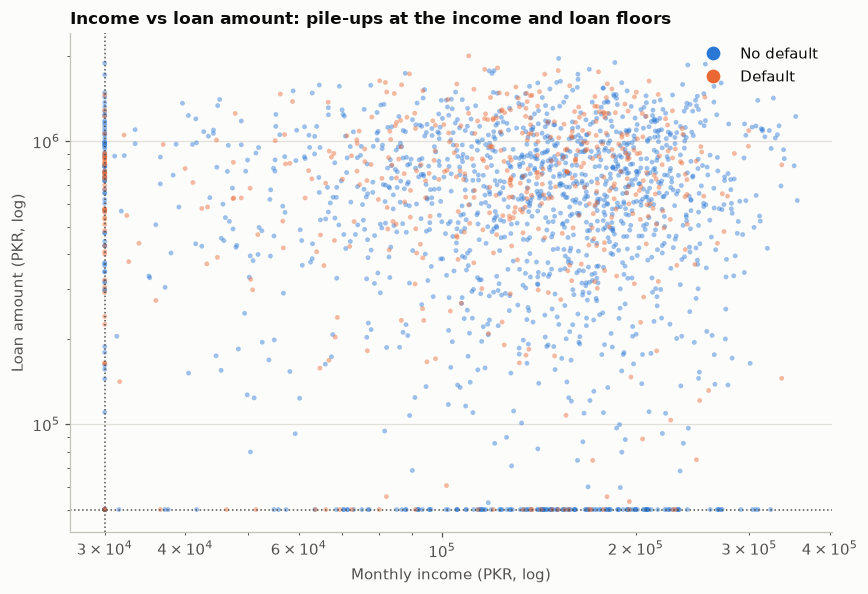

In [59]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(8, 5.5))
for flag, color, name in [(0, BLUE, "No default"), (1, ORANGE, "Default")]:
    d = eda[eda["default_90d"] == flag]
    ax.scatter(d["monthly_income_pkr"], d["loan_amount_pkr"], s=10, alpha=0.45,
               color=color, edgecolor="none")

ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(30000, color=INK2, ls=":", lw=1); ax.axhline(50000, color=INK2, ls=":", lw=1)
ax.set_xlabel("Monthly income (PKR, log)"); ax.set_ylabel("Loan amount (PKR, log)")
ax.set_title("Income vs loan amount: pile-ups at the income and loan floors")
ax.grid(axis="y", color=GRID)

handles = [Line2D([], [], marker="o", ls="", color=BLUE, markersize=8, label="No default"),
           Line2D([], [], marker="o", ls="", color=ORANGE, markersize=8, label="Default")]
ax.legend(handles=handles, frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

In [60]:
# Extreme leverage: loan relative to income
print("Loan-to-income percentiles:", eda["loan_to_income"].quantile([.5, .9, .95, .99, 1]).round(1).to_dict())
for cut in (15, 24):
    m = eda["loan_to_income"] > cut
    print(f"Loan > {cut}x monthly income: {m.sum()} customers, default rate {eda.loc[m, 'default_90d'].mean():.1%}")
print("\nThe six most extreme loan-to-income customers:")
display(eda.nlargest(6, "loan_to_income")[["monthly_income_pkr", "loan_amount_pkr", "loan_term_months", "loan_to_income", "default_90d"]].round(1))

Loan-to-income percentiles: {0.5: 4.6, 0.9: 13.6, 0.95: 20.1, 0.99: 34.4, 1.0: 63.0}
Loan > 15x monthly income: 160 customers, default rate 35.0%
Loan > 24x monthly income: 81 customers, default rate 30.9%

The six most extreme loan-to-income customers:


,monthly_income_pkr,loan_amount_pkr,loan_term_months,loan_to_income,default_90d
457,30000,1888862,24,63.0,0
1909,30000,1719651,12,57.3,0
1064,30000,1486062,12,49.5,0
503,30000,1460610,12,48.7,1
998,30000,1432540,12,47.8,0
981,30000,1372881,24,45.8,0


In [61]:
# Multivariate outliers: customers whose combination of values is unusual (Isolation Forest)
from sklearn.ensemble import IsolationForest
feat_cols = eda.select_dtypes("number").drop(columns=["default_90d", "dq_activity_inconsistent"]).columns
iso = IsolationForest(n_estimators=300, contamination=0.03, random_state=0).fit(np.log1p(eda[feat_cols]))
odd = iso.predict(np.log1p(eda[feat_cols])) == -1
print(f"Unusual combinations flagged: {odd.sum()} customers ({odd.mean():.1%})")
print(f"Default rate: flagged {eda.loc[odd, 'default_90d'].mean():.1%} vs others {eda.loc[~odd, 'default_90d'].mean():.1%}")

Unusual combinations flagged: 60 customers (3.0%)
Default rate: flagged 38.3% vs others 25.3%


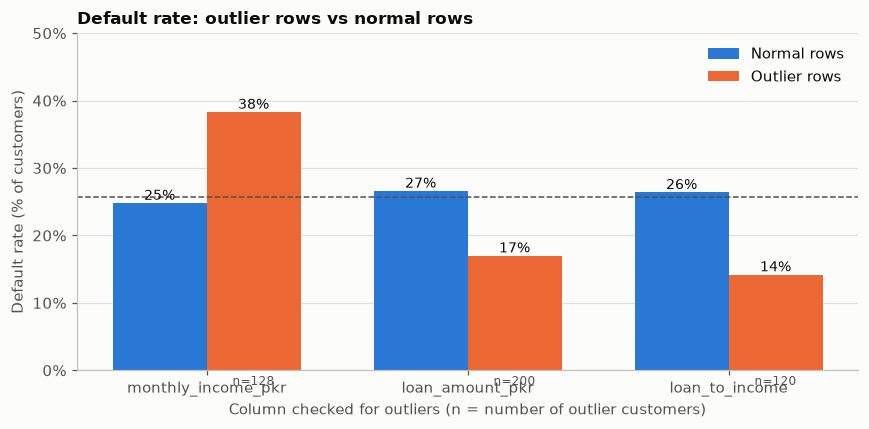

In [62]:
# Default rate: outlier rows vs normal rows (only columns with enough outliers to read: 50+)
big = outlier_summary[(outlier_summary["low_outliers"] + outlier_summary["high_outliers"]) >= 50]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(big)); w = 0.36
b1 = ax.bar(x - w / 2, big["default_rate_normal_%"] / 100, w, color=BLUE, label="Normal rows")
b2 = ax.bar(x + w / 2, big["default_rate_outliers_%"] / 100, w, color=ORANGE, label="Outlier rows")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.0%}", ha="center", va="bottom", fontsize=9)
for xi, n in zip(x, big["low_outliers"] + big["high_outliers"]):
    ax.text(xi + w / 2, -0.008, f"n={n}", ha="center", va="top", fontsize=8, color=INK2)
ax.axhline(BASE, color=INK2, ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(big.index, rotation=0)
ax.set_ylim(0, 0.5); pct_axis(ax); ax.legend(frameon=False); ax.set_title("Default rate: outlier rows vs normal rows")
ax.set_xlabel("Column checked for outliers (n = number of outlier customers)"); ax.set_ylabel("Default rate (% of customers)")
plt.tight_layout(); plt.show()

### Outlier findings
- **No data errors found.** There are no impossible values, and the unusual ones are **real, internally consistent behaviour** (very high loans, very low incomes, heavy ATM use).
- **Most columns have almost no outliers** (under 1%). The four with meaningful counts:
  - **Monthly income: 128 customers (6.4%), all on the low side.** These are essentially the **118 customers at the PKR 30,000 floor**, and they default **38.3%** vs 24.8% for others. This is a **floor (clipped) value**, so the true incomes of these customers are probably lower than recorded.
  - **Loan amount: 200 customers (10%), all on the low side.** These are mostly the **184 customers at the PKR 50,000 floor**, and they default **only 17.0%** vs 26.6%. Small loans are lower risk.
  - **Loan-to-income: 120 customers (6%)**, almost all *very low* ratios (117) with a default rate of 14.2%. Only 3 are very high on this rule.
  - **Support tickets 3+: 50 customers (2.5%)**, default rate 42.0% vs 25.2%.
- **Extreme leverage is real but not automatic default.** Loan above 15x monthly income covers 160 customers who default **35%** of the time (about 1.4x average), and above 24x covers 81 at 30.9%. The six most extreme (46-63x, all on the PKR 30,000 income floor with loans of PKR 1.4-1.9 million) include only **one** default, so very high leverage on its own is not a guarantee of default.
- **Small outlier groups with high default** (late payments 3+, 9 customers: 67%; utilisation of 95%+, 18 customers: 56%; ATM withdrawals above the fence, 15 customers: 47%) agree with the earlier EDA but are too small to rely on individually.
- **Multivariate check:** an Isolation Forest flags 60 customers (3%) with unusual *combinations* of values. They default at **38.3%** vs 25.3%, modestly higher, which fits the idea that unusual combinations tend to be riskier, but they are not errors.

**Decision: keep every customer.** Removing them would delete exactly the extremes a credit team cares about, and none looks like an error. Instead I will:
1. Use **ratios and log scales** (loan-to-income, log income) to tame skew.
2. **Cap (winsorise) at the 1st and 99th percentiles for linear models** so a handful of values cannot dominate; tree models do not need this.
3. Treat the income and loan **floor values as censored**, noting that they are a data limitation rather than precise figures.
4. Cap counts such as late payments and overdrafts at 2+.

## 4. Modelling
**Approach**
- **Candidates:** (1) the simple **risk-flag count** from the EDA as a benchmark, (2) **logistic regression** (explainable), (3) **gradient boosting** (a check for non-linear structure I might have missed).
- **Features:** repayment behaviour, utilisation, loan-to-income, tenure, balance, income, ATM use, and other profile and activity fields. **Age and region are excluded** from the main model for responsible-use reasons (age showed no pattern, region is a geographic proxy); a check below shows whether they would add anything.
- **Preparation for the linear model:** loan-to-income and income on log scales, features capped at the 1st/99th percentile (learned on training data only), counts capped (late payments and overdrafts at 2+, tickets at 3+), then standardised. Gradient boosting uses the same features without capping.
- **Validation:** repeated **stratified 5-fold cross-validation** (3 repeats). Every customer has one row, so there is no leakage between folds. All tuning (regularisation strength, boosting settings) happens **inside each training fold**, so the scores are honest.
- **Metrics:** ROC-AUC as the headline; PR-AUC; precision, recall, F1 and F2 at a chosen review volume; calibration; and the default rate per risk band. Accuracy is not used (always predicting "no default" gives 74% accuracy). No resampling: the default rate is 25.7%, so class imbalance is mild.

In [63]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_curve)

# ---- Features ----
# Main model EXCLUDES age and region (see responsible-use notes): age showed no pattern, region is a geographic proxy.
# Loan amount and income are replaced by loan-to-income (+ log income) to avoid duplicated information.
def build_credit_features(d):
    X = pd.DataFrame(index=d.index)
    X["late_payments_6m"] = d["late_payment_count_6m"].clip(upper=2)
    X["overdrafts_6m"] = d["overdraft_events_6m"].clip(upper=2)
    X["credit_utilization_pct"] = d["credit_utilization_pct"]
    X["log_loan_to_income"] = np.log(d["loan_amount_pkr"] / d["monthly_income_pkr"])
    X["log_income"] = np.log(d["monthly_income_pkr"])
    X["log_avg_balance"] = np.log1p(d["avg_balance_pkr"])
    X["tenure_months"] = d["tenure_months"]
    X["atm_withdrawals_30d"] = d["atm_withdrawals_30d"]
    X["support_tickets_90d"] = d["support_tickets_90d"].clip(upper=3)
    X["interest_rate_pct"] = d["interest_rate_pct"]
    X["loan_term_months"] = d["loan_term_months"]
    X["has_salary_account"] = d["has_salary_account"]
    X["kyc_enhanced"] = (d["kyc_level"] == "Enhanced").astype(int)
    X["app_logins_30d"] = d["app_logins_30d"]
    X["txn_count_30d"] = d["txn_count_30d"]
    X["log_card_spend"] = np.log1p(d["card_spend_30d_pkr"])
    return X

def winsorise(X, lo=0.01, hi=0.99, bounds=None):
    """Cap at the 1st/99th percentile (bounds learned on training data only)."""
    if bounds is None:
        bounds = (X.quantile(lo), X.quantile(hi))
    return X.clip(bounds[0], bounds[1], axis=1), bounds

X_cr = build_credit_features(eda)
y_cr = eda["default_90d"].values
print("Features:", X_cr.shape[1], "| customers:", len(y_cr), "| default rate:", f"{y_cr.mean():.1%}")

Features: 16 | customers: 2000 | default rate: 25.7%


In [64]:
# ---- Model comparison: repeated stratified 5-fold CV. Tuning happens INSIDE each training fold (nested), so scores are honest. ----
# Customers have one row each, so there is no leakage between folds.
class WinsorLR:
    """Logistic regression on winsorised + standardised features; C chosen by inner CV (ROC-AUC)."""
    def fit(self, X, y):
        Xw, self.bounds = winsorise(X)
        self.model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=[0.003, 0.01, 0.03, 0.1, 0.3, 1, 3], cv=5, scoring="roc_auc", max_iter=3000))
        self.model.fit(Xw, y); return self
    def predict_proba(self, X):
        return self.model.predict_proba(winsorise(X, bounds=self.bounds)[0])

class TunedGB:
    def fit(self, X, y):
        grid = {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "min_samples_leaf": [20, 50], "max_iter": [100, 250]}
        self.model = GridSearchCV(HistGradientBoostingClassifier(l2_regularization=1.0, early_stopping=False, random_state=0),
                                  grid, cv=3, scoring="roc_auc", n_jobs=-1).fit(X, y); return self
    def predict_proba(self, X):
        return self.model.predict_proba(X)

def flag_count(d):
    return (((d["late_payment_count_6m"] >= 1).astype(int) + (d["overdraft_events_6m"] >= 1).astype(int)
             + (d["credit_utilization_pct"] > 55).astype(int) + (d["loan_amount_pkr"] / d["monthly_income_pkr"] > 9).astype(int)
             + (d["tenure_months"] <= 25).astype(int) + (d["atm_withdrawals_30d"] > 10).astype(int))).values.astype(float)

N_REP, N_FOLD = 3, 5
names = ["Risk-flag count", "Logistic regression", "Gradient boosting"]
oof = {}; fold_of = {}
jitter = np.random.default_rng(0).uniform(0, 0.01, len(y_cr))
for r in range(N_REP):
    for n in names: oof[(r, n)] = np.zeros(len(y_cr))
    fold_of[r] = np.zeros(len(y_cr), dtype=int)
    for f, (tr, te) in enumerate(StratifiedKFold(N_FOLD, shuffle=True, random_state=r).split(X_cr, y_cr)):
        fold_of[r][te] = f
        oof[(r, "Risk-flag count")][te] = flag_count(eda.iloc[te]) + jitter[te]
        oof[(r, "Logistic regression")][te] = WinsorLR().fit(X_cr.iloc[tr], y_cr[tr]).predict_proba(X_cr.iloc[te])[:, 1]
        oof[(r, "Gradient boosting")][te] = TunedGB().fit(X_cr.iloc[tr], y_cr[tr]).predict_proba(X_cr.iloc[te])[:, 1]
print("Cross-validation finished:", N_REP, "repeats x", N_FOLD, "folds")

d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
d:\fraud-monitoring-credit-ri

Cross-validation finished: 3 repeats x 5 folds


In [65]:
def fbeta(p, r, beta):
    return 0 if p + r == 0 else (1 + beta**2) * p * r / (beta**2 * p + r)

def topk_metrics(y, s, share):
    k = int(round(len(y) * share)); o = np.argsort(-s, kind="stable")[:k]; tp = y[o].sum()
    p, r = tp / k, tp / y.sum()
    return p, r, fbeta(p, r, 1), fbeta(p, r, 2)

rows = []
for n in names:
    recs = []
    for r in range(N_REP):
        s, fo = oof[(r, n)], fold_of[r]
        rec = {"ROC-AUC": np.mean([roc_auc_score(y_cr[fo == f], s[fo == f]) for f in range(N_FOLD)]),
               "PR-AUC": np.mean([average_precision_score(y_cr[fo == f], s[fo == f]) for f in range(N_FOLD)])}
        pr = []
        for f in range(N_FOLD):
            m = fo == f; pr.append(topk_metrics(y_cr[m], s[m], 0.20))
        rec.update(dict(zip(["precision@top20%", "recall@top20%", "F1@top20%", "F2@top20%"], np.mean(pr, axis=0))))
        if n != "Risk-flag count":
            rec["Brier"] = brier_score_loss(y_cr, s); rec["log loss"] = log_loss(y_cr, np.clip(s, 1e-6, 1 - 1e-6))
        recs.append(rec)
    rows.append(pd.DataFrame(recs).mean().rename(n))
results = pd.DataFrame(rows)
print(f"Stratified 5-fold CV x {N_REP} repeats | default rate {y_cr.mean():.3f} | always-'no default' accuracy would be {1 - y_cr.mean():.1%}")
display(results.round(3))

Stratified 5-fold CV x 3 repeats | default rate 0.257 | always-'no default' accuracy would be 74.4%


,ROC-AUC,PR-AUC,precision@top20%,recall@top20%,F1@top20%,F2@top20%,Brier,log loss
Risk-flag count,0.731,0.524,0.529,0.413,0.464,0.432,NaN,NaN
Logistic regression,0.786,0.593,0.603,0.470,0.529,0.492,0.150,0.463
Gradient boosting,0.761,0.565,0.568,0.443,0.497,0.463,0.156,0.479


### Bootstrap: are the differences real? (supplementary)

In [66]:
# Are the differences real? Paired bootstrap on customers (repeat 0 out-of-fold scores, ROC-AUC computed fold-wise)
rng = np.random.default_rng(7); fo0 = fold_of[0]
def cv_auc(idx, s):
    return np.mean([roc_auc_score(y_cr[idx[fo0[idx] == f]], s[idx[fo0[idx] == f]]) for f in range(N_FOLD)])
pairs = [("Logistic regression", "Risk-flag count"), ("Logistic regression", "Gradient boosting"), ("Gradient boosting", "Risk-flag count")]
diffs = {p: [] for p in pairs}
for _ in range(300):
    idx = rng.integers(0, len(y_cr), len(y_cr))
    a = {n: cv_auc(idx, oof[(0, n)]) for n in names}
    for (m1, m2) in pairs: diffs[(m1, m2)].append(a[m1] - a[m2])
boot = pd.DataFrame({f"{m1} minus {m2}": {"mean AUC diff": np.mean(d), "95% low": np.percentile(d, 2.5), "95% high": np.percentile(d, 97.5),
                                           "P(first better)": np.mean(np.array(d) > 0)} for (m1, m2), d in diffs.items()}).T
display(boot.round(3))

,mean AUC diff,95% low,95% high,P(first better)
Logistic regression minus Risk-flag count,0.056,0.033,0.074,1.000
Logistic regression minus Gradient boosting,0.025,0.014,0.036,1.000
Gradient boosting minus Risk-flag count,0.030,0.011,0.051,0.997


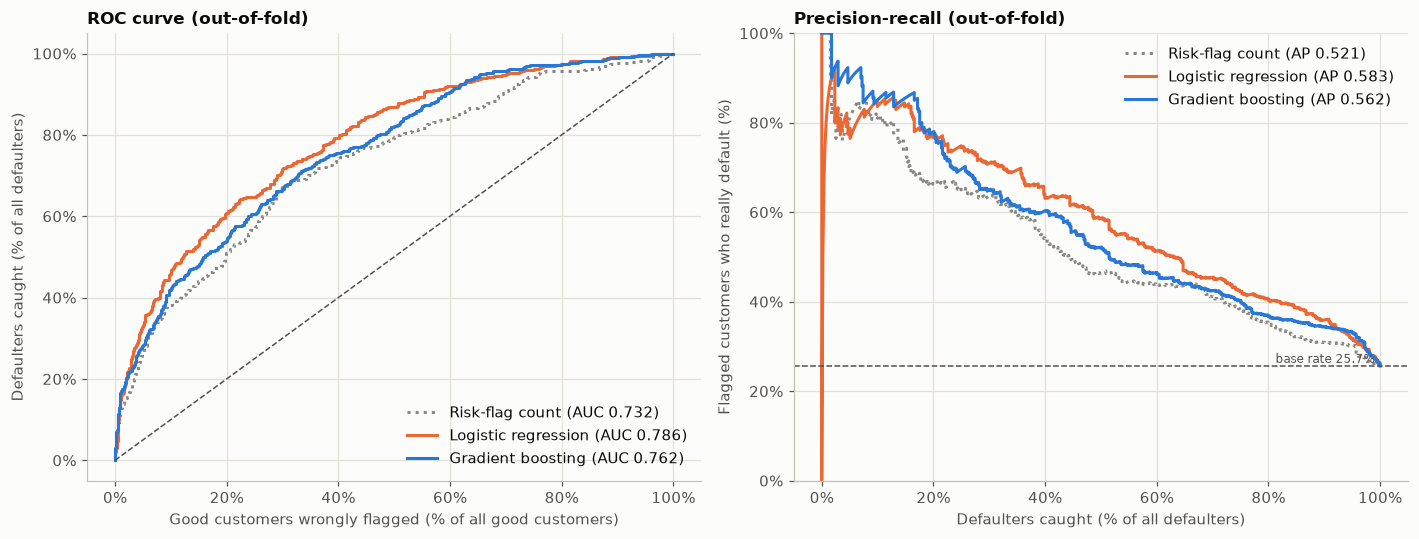

In [67]:
# ROC and precision-recall curves on out-of-fold predictions (repeat 0)
styles = {"Risk-flag count": (MUTED, ":"), "Logistic regression": (ORANGE, "-"), "Gradient boosting": (BLUE, "-")}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, (color, ls) in styles.items():
    s = oof[(0, n)]
    fpr, tpr, _ = roc_curve(y_cr, s); axes[0].plot(fpr, tpr, color=color, ls=ls, lw=2, label=f"{n} (AUC {roc_auc_score(y_cr, s):.3f})")
    pr, rc, _ = precision_recall_curve(y_cr, s); axes[1].plot(rc, pr, color=color, ls=ls, lw=2, label=f"{n} (AP {average_precision_score(y_cr, s):.3f})")
axes[0].plot([0, 1], [0, 1], color=INK2, ls="--", lw=1)
axes[0].set_xlabel("Good customers wrongly flagged (% of all good customers)"); axes[0].set_ylabel("Defaulters caught (% of all defaulters)")
axes[0].set_title("ROC curve (out-of-fold)"); axes[0].legend(frameon=False, loc="lower right"); axes[0].grid(axis="x", color=GRID)
axes[1].axhline(y_cr.mean(), color=INK2, ls="--", lw=1)
axes[1].text(0.99, y_cr.mean(), f" base rate {y_cr.mean():.1%}", ha="right", va="bottom", fontsize=8, color=INK2)
axes[1].set_xlabel("Defaulters caught (% of all defaulters)"); axes[1].set_ylabel("Flagged customers who really default (%)"); axes[1].set_ylim(0, 1)
axes[1].set_title("Precision-recall (out-of-fold)"); axes[1].legend(frameon=False); axes[1].grid(axis="x", color=GRID)
pct_axis(axes[1], "y"); pct_axis(axes[1], "x"); pct_axis(axes[0], "y"); pct_axis(axes[0], "x")
plt.tight_layout(); plt.show()

**Reading (model comparison):**
- **Logistic regression is the best model**: ROC-AUC 0.786 vs 0.761 for gradient boosting and 0.731 for the risk-flag count; PR-AUC 0.593 vs 0.565 and 0.524 (the base rate is 0.257).
- **The gaps are real, not noise.** The paired bootstrap puts logistic regression ahead of gradient boosting by **+0.025 AUC (95% interval +0.014 to +0.036)** and ahead of the flag count by **+0.056 (+0.033 to +0.074)**. The flag count's thresholds were read off these same customers, so it had an advantage and still lost.
- **Simpler wins again.** Gradient boosting did not find structure that the linear model missed, which fits the EDA (steady, independent effects). This supports recommending the **explainable logistic regression**.
- **If the bank reviews the top 20% of customers by score:** about **60% of those flagged default** (vs 25.7% overall, 2.3x), catching about **47% of all defaulters** (F1 0.53, F2 0.49).

### Risk bands: does the score separate customers in a way a credit team can use?
Customers are ranked by score *within each validation fold* (so no customer is scored by a model that saw them), then grouped: **High = top 20%, Medium = next 30%, Low = bottom 50%**.

,customers,defaults,default_rate,avg_predicted,share_of_customers,share_of_all_defaults,lift_vs_avg
band,,,,,,,
Low,1000,107,0.107,0.107,0.5,0.209,0.417
Medium,600,162,0.270,0.290,0.3,0.316,1.053
High,400,244,0.610,0.576,0.2,0.476,2.378


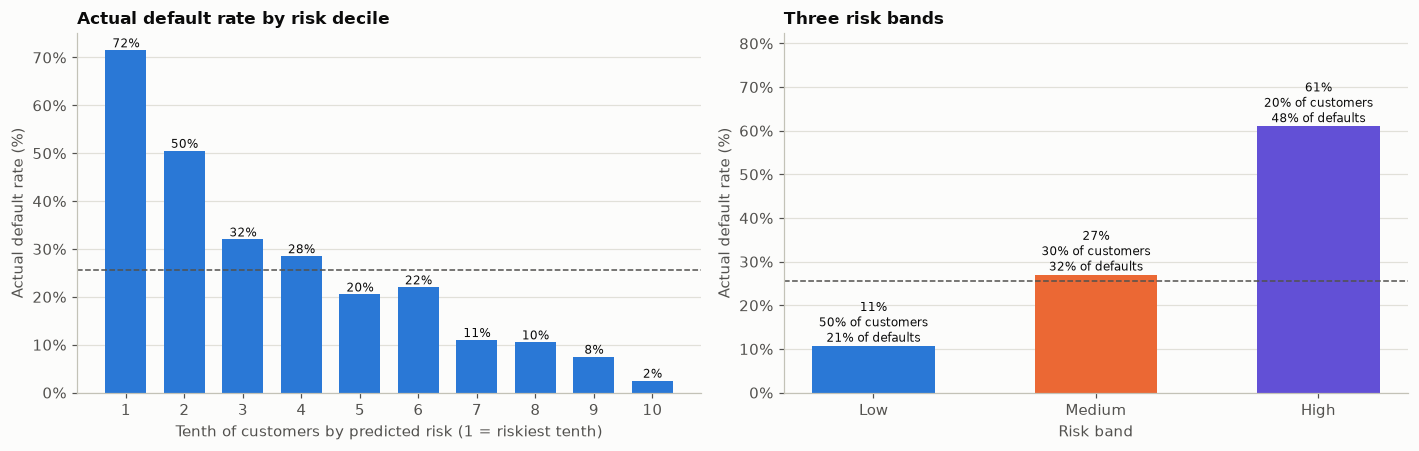

In [68]:
# Risk bands from the logistic regression: within each fold, top 20% = High, next 30% = Medium, bottom 50% = Low
s_lr, fo0 = oof[(0, "Logistic regression")], fold_of[0]
band = np.empty(len(y_cr), dtype=object); decile = np.zeros(len(y_cr), dtype=int)
for f in range(N_FOLD):
    idx = np.where(fo0 == f)[0]; order = idx[np.argsort(-s_lr[idx], kind="stable")]; n = len(idx)
    band[order[: int(n * 0.20)]] = "High"; band[order[int(n * 0.20): int(n * 0.50)]] = "Medium"; band[order[int(n * 0.50):]] = "Low"
    for d in range(10): decile[order[int(n * d / 10): int(n * (d + 1) / 10)]] = d + 1
bands = pd.DataFrame({"band": band, "default": y_cr, "score": s_lr})
tab = bands.groupby("band").agg(customers=("default", "size"), defaults=("default", "sum"), default_rate=("default", "mean"),
                                avg_predicted=("score", "mean")).loc[["Low", "Medium", "High"]]
tab["share_of_customers"] = tab["customers"] / len(y_cr); tab["share_of_all_defaults"] = tab["defaults"] / y_cr.sum()
tab["lift_vs_avg"] = tab["default_rate"] / y_cr.mean()
display(tab.round(3))

dec = pd.DataFrame({"decile": decile, "default": y_cr}).groupby("decile")["default"].agg(["size", "mean"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(dec.index, dec["mean"], color=BLUE, width=0.7); axes[0].axhline(y_cr.mean(), color=INK2, ls="--", lw=1)
for d, v in dec["mean"].items(): axes[0].text(d, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(dec.index); axes[0].set_xticklabels([f"{d}" for d in dec.index]); axes[0].set_xlabel("Tenth of customers by predicted risk (1 = riskiest tenth)"); axes[0].set_ylabel("Actual default rate (%)")
axes[0].set_title("Actual default rate by risk decile"); pct_axis(axes[0])
cols = {"Low": BLUE, "Medium": "#eb6834", "High": "#6250d6"}
axes[1].bar(tab.index, tab["default_rate"], color=[cols[b] for b in tab.index], width=0.55); axes[1].axhline(y_cr.mean(), color=INK2, ls="--", lw=1)
for i, (b, row) in enumerate(tab.iterrows()):
    axes[1].text(i, row["default_rate"], f"{row['default_rate']:.0%}\n{row['share_of_customers']:.0%} of customers\n{row['share_of_all_defaults']:.0%} of defaults",
                 ha="center", va="bottom", fontsize=8)
axes[1].set_ylim(0, tab["default_rate"].max() * 1.35); pct_axis(axes[1]); axes[1].set_xlabel("Risk band"); axes[1].set_ylabel("Actual default rate (%)"); axes[1].set_title("Three risk bands")
plt.tight_layout(); plt.show()

**Reading (risk bands):**
- The actual default rate falls steadily from **71.5% in the riskiest decile to 2.5% in the safest**, with only one tiny reversal (deciles 5 and 6, 20.5% vs 22.0%). So the ranking is meaningful across the whole range, not just at the extremes.
- **High band (20% of customers): 61% default**, which is 2.4x the average, and it contains **48% of all defaulters**.
- **Medium band (30%): 27% default**, about the average.
- **Low band (50%): 10.7% default**, about 0.4x the average, holding only **21% of defaulters**. The High band defaults about **5.7x as often** as the Low band.
- The High band is still **39% good customers**, so the action attached to it should be a review or outreach rather than a decline.

### Calibration: do the probabilities mean what they say? (supplementary check)

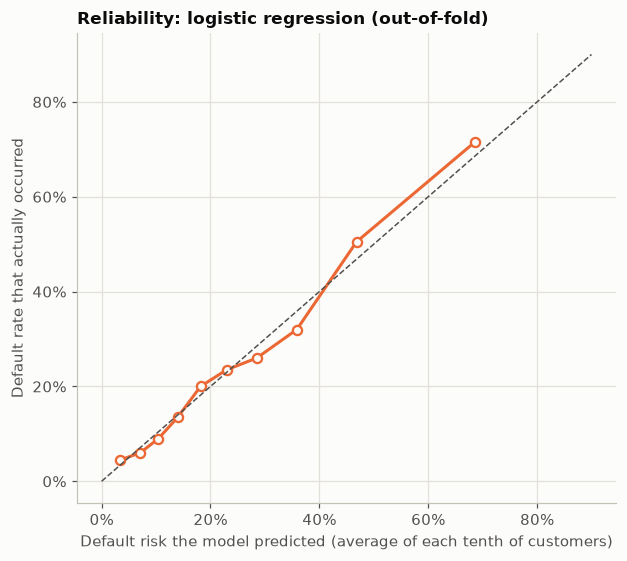

Brier score 0.1492 vs 0.1907 for predicting the average for everyone (skill 21.7%) | mean predicted 0.256 vs observed 0.257
Largest gap between predicted and observed across deciles: 0.039


In [69]:
# Calibration: do predicted probabilities match actual default rates?
q = pd.qcut(s_lr, 10, duplicates="drop")
rel = pd.DataFrame({"pred": s_lr, "obs": y_cr, "bin": q}).groupby("bin", observed=True).agg(pred=("pred", "mean"), obs=("obs", "mean"), n=("obs", "size"))
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot(rel["pred"], rel["obs"], color=ORANGE, marker="o", lw=2, ms=6, mfc=SURF, mew=1.5)
ax.plot([0, 0.9], [0, 0.9], color=INK2, ls="--", lw=1)
ax.set_xlabel("Default risk the model predicted (average of each tenth of customers)"); ax.set_ylabel("Default rate that actually occurred")
ax.set_title("Reliability: logistic regression (out-of-fold)"); pct_axis(ax, "x"); pct_axis(ax, "y"); ax.grid(axis="x", color=GRID)
plt.tight_layout(); plt.show()
base_brier = brier_score_loss(y_cr, np.full(len(y_cr), y_cr.mean()))
print(f"Brier score {brier_score_loss(y_cr, s_lr):.4f} vs {base_brier:.4f} for predicting the average for everyone "
      f"(skill {1 - brier_score_loss(y_cr, s_lr) / base_brier:.1%}) | mean predicted {s_lr.mean():.3f} vs observed {y_cr.mean():.3f}")
print("Largest gap between predicted and observed across deciles:", f"{(rel['pred'] - rel['obs']).abs().max():.3f}")

**Reading (calibration):** the model's probabilities are **well calibrated without any extra step**: the average prediction matches the observed default rate (25.6% vs 25.7%) and no decile is off by more than about 4 percentage points. Brier score is 0.149 vs 0.191 for predicting the average for everyone (about 22% better). (This is different from the fraud model, where strong regularisation squeezed the scores and a calibration step was needed.) So a predicted 40% really means about 4 in 10 default, and probability cut-offs can be used for decisions.

### How many customers should be reviewed? (precision, recall, F1 and F2 vs review volume)

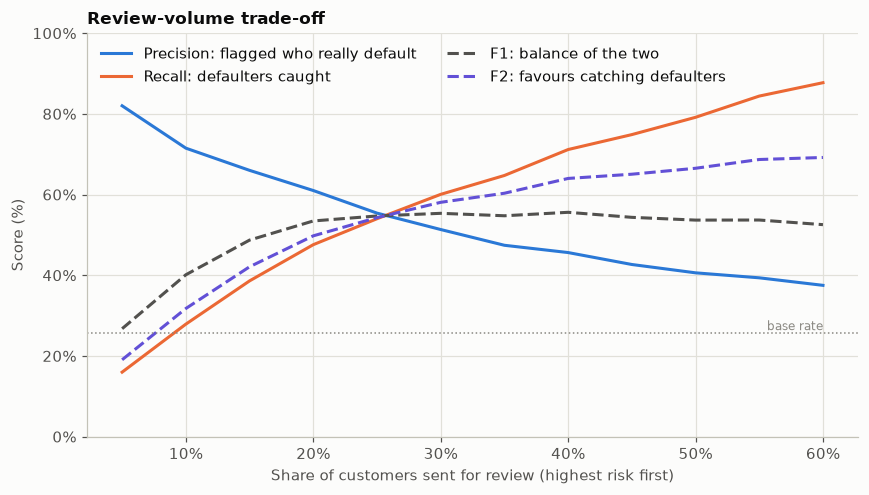

F1 peaks at reviewing 40% of customers (F1 0.556); F2 peaks at 60% (F2 0.692)


,precision,recall,F1,F2
review share,,,,
0.1,0.715,0.279,0.401,0.318
0.2,0.610,0.476,0.535,0.498
0.3,0.513,0.600,0.553,0.581
0.4,0.456,0.712,0.556,0.640
0.5,0.406,0.791,0.537,0.665


In [70]:
# How many customers to review? Precision, recall, F1 and F2 as the review share grows (logistic regression, out-of-fold)
shares = np.arange(0.05, 0.61, 0.05)
rows = []
for sh in shares:
    m = np.mean([topk_metrics(y_cr[fo0 == f], s_lr[fo0 == f], sh) for f in range(N_FOLD)], axis=0)
    rows.append({"review share": sh, "precision": m[0], "recall": m[1], "F1": m[2], "F2": m[3]})
th = pd.DataFrame(rows).set_index("review share")
fig, ax = plt.subplots(figsize=(8, 4.6))
for col, color, ls in [("precision", BLUE, "-"), ("recall", ORANGE, "-"), ("F1", INK2, "--"), ("F2", "#6250d6", "--")]:
    ax.plot(th.index, th[col], color=color, ls=ls, lw=2, label={"precision": "Precision: flagged who really default", "recall": "Recall: defaulters caught", "F1": "F1: balance of the two", "F2": "F2: favours catching defaulters"}[col])
ax.axhline(y_cr.mean(), color=MUTED, ls=":", lw=1); ax.text(0.6, y_cr.mean(), " base rate", va="bottom", ha="right", fontsize=8, color=MUTED)
ax.set_xlabel("Share of customers sent for review (highest risk first)"); ax.set_ylabel("Score (%)"); ax.set_ylim(0, 1)
pct_axis(ax, "x"); pct_axis(ax, "y"); ax.grid(axis="x", color=GRID); ax.legend(frameon=False, ncol=2)
ax.set_title("Review-volume trade-off")
plt.tight_layout(); plt.show()
print(f"F1 peaks at reviewing {th['F1'].idxmax():.0%} of customers (F1 {th['F1'].max():.3f}); F2 peaks at {th['F2'].idxmax():.0%} (F2 {th['F2'].max():.3f})")
display(th.loc[[0.10, 0.20, 0.30, 0.40, 0.50]].round(3))

**Reading (review volume):**
- **Review volume is a business choice, not a statistical one.** Precision falls and recall rises as more customers are reviewed: the **top 10%** has 72% precision but catches only 28% of defaulters; the **top 20%** gives 61% / 48%; the **top 30%** gives 51% / 60%; the **top 40%** gives 46% / 71%.
- **F1 is flat from about 20% to 50%** (0.535 to 0.556, peak at 40%), so it does not point to a single best volume. **F2**, which favours recall, keeps rising to 60%. This is why I treat F1 and F2 as reference points only.
- **My suggestion:** start with the **top 20% (High band)** for active review, since that is where precision is highest, and add the Medium band for lighter-touch monitoring. The final volume should come from the team's **review capacity** and the relative cost of a missed default vs an unnecessary review.

### What drives the score? (explainability)

d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


Chosen regularisation C: 0.03


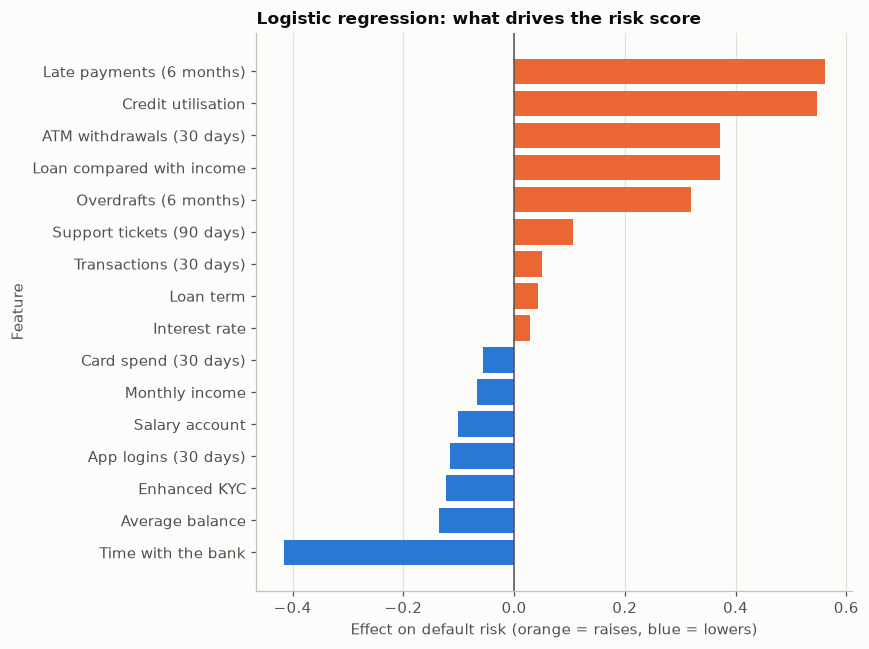

,coef,odds_ratio_per_sd
late_payments_6m,0.561,1.752
credit_utilization_pct,0.547,1.729
atm_withdrawals_30d,0.373,1.452
log_loan_to_income,0.371,1.449
overdrafts_6m,0.319,1.376
support_tickets_90d,0.107,1.113
txn_count_30d,0.050,1.051
loan_term_months,0.043,1.043
interest_rate_pct,0.030,1.030
log_card_spend,-0.056,0.946


In [71]:
# Final explainable model on all data: coefficients per 1 standard deviation (after winsorising)
Xw_all, final_bounds = winsorise(X_cr)
final_lr = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=[0.003, 0.01, 0.03, 0.1, 0.3, 1, 3], cv=5, scoring="roc_auc", max_iter=3000)).fit(Xw_all, y_cr)
coef = pd.Series(final_lr[-1].coef_[0], index=X_cr.columns).sort_values()
print("Chosen regularisation C:", final_lr[-1].C_[0])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(nice_names(coef.index), coef.values, color=[ORANGE if v > 0 else BLUE for v in coef.values])
ax.axvline(0, color=INK2, lw=1); ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Effect on default risk (orange = raises, blue = lowers)"); ax.set_ylabel("Feature")
ax.set_title("Logistic regression: what drives the risk score")
plt.tight_layout(); plt.show()
odds = pd.DataFrame({"coef": coef, "odds_ratio_per_sd": np.exp(coef)}).sort_values("coef", ascending=False)
display(odds.round(3))

**Reading (drivers):** each coefficient is the change in the log-odds of default for a one-standard-deviation change in that feature; the odds ratio column makes it easier to read.
- **Raises risk:** **late payments** (odds x1.75 per std-dev), **credit utilisation** (x1.73), **ATM withdrawals** (x1.45), **loan-to-income** (x1.45), **overdrafts** (x1.38).
- **Lowers risk:** **longer tenure** (x0.66, the strongest protective factor), a higher average balance (x0.87), Enhanced KYC (x0.88), more app logins (x0.89) and a salary account (x0.90).
- **Little or no effect:** interest rate, loan term, transaction count, card spend and income (once loan-to-income and balance are in the model). This matches the EDA.
- The model is transparent: each decision can be explained with its **top contributing factors** (for example, "2 late payments, 80% utilisation, short tenure").

### Responsible-use checks: sensitive attributes and group consistency
(1) Would adding **age and region** improve prediction? (2) Does the score behave consistently across regions, KYC levels and age groups?

In [72]:
# Responsible-use checks: (1) would age and region add predictive value? (2) does the score treat groups consistently?
X_sens = X_cr.copy()
X_sens["age"] = eda["age"].values
X_sens = X_sens.join(pd.get_dummies(eda["region"], prefix="region", drop_first=True, dtype=int))
aucs = {"without age/region (main model)": [], "with age + region": []}
for r in range(N_REP):
    for f, (tr, te) in enumerate(StratifiedKFold(N_FOLD, shuffle=True, random_state=r).split(X_cr, y_cr)):
        for label, XX in [("without age/region (main model)", X_cr), ("with age + region", X_sens)]:
            m = WinsorLR().fit(XX.iloc[tr], y_cr[tr]); aucs[label].append(roc_auc_score(y_cr[te], m.predict_proba(XX.iloc[te])[:, 1]))
print({k: round(float(np.mean(v)), 4) for k, v in aucs.items()})

# Group consistency using the out-of-fold bands
audit = eda[["region", "kyc_level", "age"]].copy()
audit["age_group"] = pd.cut(audit["age"], [19, 30, 40, 50, 60], labels=["20-30", "31-40", "41-50", "51-60"])
audit["High band"] = (bands["band"].values == "High").astype(int); audit["default"] = y_cr; audit["predicted"] = s_lr
rows = []
for col in ["region", "kyc_level", "age_group"]:
    g = audit.groupby(col, observed=True).agg(customers=("default", "size"), actual_default_rate=("default", "mean"),
                                              avg_predicted=("predicted", "mean"), share_in_High_band=("High band", "mean"))
    g.insert(0, "group", col); rows.append(g.reset_index().rename(columns={col: "value"}))
display(pd.concat(rows).set_index(["group", "value"]).round(3))

d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
d:\fraud-monitoring-credit-ri

{'without age/region (main model)': 0.7862, 'with age + region': 0.7854}


d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
d:\fraud-monitoring-credit-risk\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


customers  actual_default_rate  avg_predicted  share_in_High_band
group     value                                                                       
region    Karachi          804                0.243          0.250               0.190
          Lahore           464                0.269          0.264               0.209
          Islamabad        249                0.233          0.257               0.241
          Others           483                0.280          0.256               0.186
kyc_level Basic           1064                0.282          0.279               0.240
          Enhanced         936                0.228          0.230               0.155
age_group 20-30            537                0.248          0.257               0.199
          31-40            486                0.282          0.264               0.216
          41-50            479                0.276          0.257               0.190
          51-60            498                0.223          0.245               0.195

**Reading (responsible use):**
- **Age and region add nothing:** AUC is 0.7854 with them and 0.7862 without. There is no performance reason to use sensitive or proxy attributes, so they stay **out of the score**.
- **Predictions track actual default rates across groups.** Average predicted risk is within about 2.5 percentage points of actual default for every region, KYC level and age group. The score is not systematically over- or under-predicting for one group.
- **KYC level** shows the largest gap in how often customers land in the High band (24% for Basic vs 15.5% for Enhanced), but it reflects a *real* gap in outcomes (28.2% vs 22.8% actual default), not a miscalibration.
- **Islamabad** is flagged slightly more than its actual default rate would suggest (predicted 25.7% vs actual 23.3%), and "Others" slightly less (25.6% vs 28.0%). With only 249 and 483 customers, this is within noise, but it is the kind of difference the bank should **monitor** as data grows.

### A deployable scorer

In [73]:
# Deployable scorer: final logistic regression + bands based on score cut-offs learned from the out-of-fold scores
cut_high = np.quantile(s_lr, 0.80); cut_med = np.quantile(s_lr, 0.50)

def score_customers(df_new):
    """Default probability and risk band for new customers (same columns as the raw file)."""
    d = df_new.copy(); d["loan_to_income"] = d["loan_amount_pkr"] / d["monthly_income_pkr"]
    Xn = winsorise(build_credit_features(d), bounds=final_bounds)[0]
    p = final_lr.predict_proba(Xn)[:, 1]
    return pd.DataFrame({"default_probability": p, "risk_band": np.where(p >= cut_high, "High", np.where(p >= cut_med, "Medium", "Low"))},
                        index=df_new.index)

demo = score_customers(eda.head(2000))
print(f"Cut-offs: High >= {cut_high:.1%} predicted default probability, Medium >= {cut_med:.1%}")
print("Demo (in-sample, illustration only):", demo["risk_band"].value_counts().to_dict())

Cut-offs: High >= 40.4% predicted default probability, Medium >= 20.4%
Demo (in-sample, illustration only): {'Low': 1001, 'Medium': 602, 'High': 397}


### Modelling summary and recommendation
| | ROC-AUC | PR-AUC | Precision (top 20%) | Recall (top 20%) |
|---|---|---|---|---|
| Risk-flag count | 0.731 | 0.524 | 52.9% | 41.3% |
| **Logistic regression** | **0.786** | **0.593** | **60.3%** | **47.0%** |
| Gradient boosting | 0.761 | 0.565 | 56.8% | 44.3% |

**Recommendation: use the regularised logistic regression as the credit-risk score**, with three bands (High 20%, Medium 30%, Low 50%).
- **Best on every metric**, with the improvement over the alternatives statistically supported.
- **Explainable** (clear drivers, and the plain risk factors behind each flag), **well calibrated** (probabilities can be used directly) and **consistent across groups**, with no sensitive attributes in it.
- A more complex model (gradient boosting) did **not** add value.

### How a credit team should use it responsibly
| Band | Share | Default rate | Suggested action |
|---|---|---|---|
| **High** | Top 20% | about 61% | **Human review before any new credit or limit increase**, proactive outreach (payment reminders, repayment plan), tighter monitoring |
| **Medium** | Next 30% | about 27% | Early-warning monitoring, light reminders, no restriction |
| **Low** | Bottom 50% | about 11% | Normal service |

**Principles**
1. **Support decisions, don't make them.** About 4 in 10 customers in the High band are good customers, so the output should trigger a **review or a supportive conversation**, never an automatic decline.
2. **Explain every flag.** Show the risk factors present on the customer's record with each flag, so analysts (and, where needed, customers) can understand and challenge the result.
3. **No sensitive attributes, and keep checking.** Age and region are excluded; re-run the group checks regularly as data grows.
4. **Monitor and re-validate.** Track default rate per band, calibration and drift every month or quarter, and re-fit when the portfolio changes.
5. **Allow human override** and record the reasons, so the team can catch cases the model cannot see.

**Limitations to state openly**
- Only **2,000 customers from a single snapshot**, so estimates are uncertain (the bootstrap intervals show how much).
- The data covers customers who **already received credit**. The score may not apply to people who were never approved (selection bias).
- Several 30-day activity fields were **internally inconsistent** and income and loan values are floored (see the cleaning section); fixing these at the source would improve reliability.
- Default is a **90-day outcome**; the score says nothing about longer horizons.

## 5. Control panel: how the bank tunes who gets flagged
**The question this answers:** *"Too many good customers are being marked as likely defaulters (or too many defaulters are slipping through). Can we change that ourselves?"* **Yes, without retraining anything.** The model outputs a default probability; the only decision left is **where to draw the "needs review" line**. That line is one dial, set in two ways:

| Way to set the dial | Parameter | Use it when |
|---|---|---|
| **By risk** | `prob_threshold` (e.g. flag at 40% predicted default) | "We only want to review customers who are at least this likely to default" (valid because the probabilities are well calibrated, see section 4) |
| **By capacity** | `review_share` (e.g. top 20% of customers) | "Our credit team can review about N customers" |

| Symptom | What to turn |
|---|---|
| **Too many good customers flagged** | Raise the threshold (stricter), or lower `review_share` |
| **Too many defaulters slipping through** | Lower the threshold (more generous), or raise `review_share` |
| **Not sure what the right balance is** | State the goal in `credit_find_setting(...)` and let it find the setting |
| **Portfolio or default rate changes** | Re-check calibration; capacity-based settings stay valid, probability thresholds may need adjusting |

*All figures are out-of-fold estimates on these 2,000 customers.*

,customers flagged (%),flagged who really default (precision),defaulters caught (recall),GOOD customers wrongly flagged (% of all good),good customers flagged per defaulter caught,defaulters MISSED (% of all defaulters),F1,min probability flagged
flag if P(default) >=,,,,,,,,
15%,0.628,0.363,0.889,0.538,1.754,0.111,0.516,0.150
20%,0.507,0.404,0.799,0.406,1.473,0.201,0.537,0.200
30%,0.324,0.499,0.632,0.219,1.003,0.368,0.558,0.300
40%,0.206,0.604,0.485,0.110,0.655,0.515,0.538,0.400
50%,0.126,0.690,0.339,0.052,0.448,0.661,0.455,0.501
60%,0.072,0.771,0.216,0.022,0.297,0.784,0.338,0.600
70%,0.043,0.837,0.140,0.009,0.194,0.860,0.240,0.702


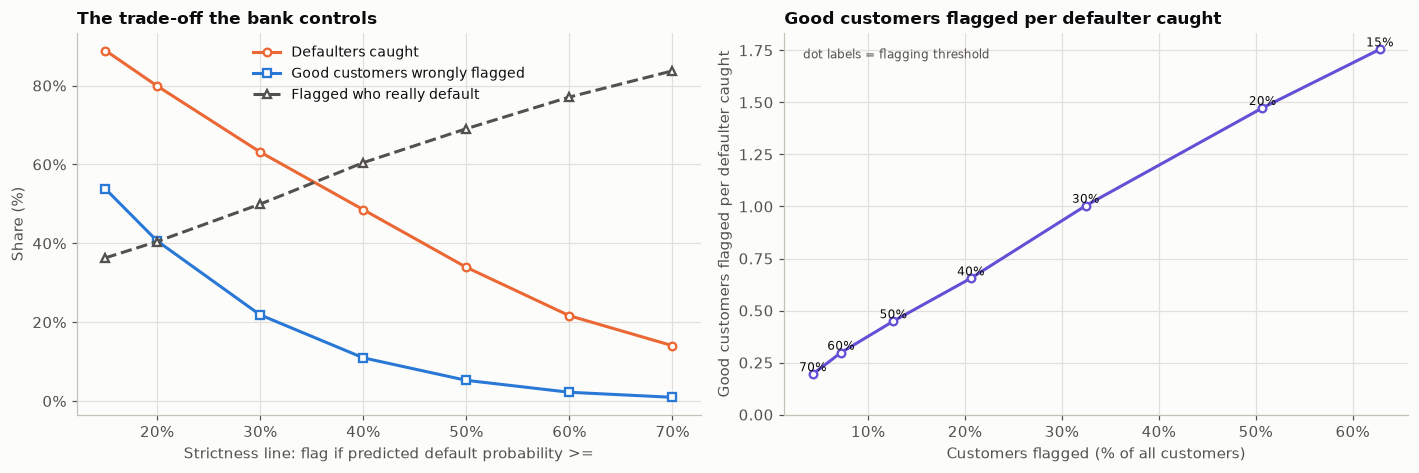

In [74]:
# ======================= CONTROL PANEL: credit review settings =======================
# The bank turns ONE dial: how strict the "needs review" line is. Two equivalent ways to set it:
#   (a) prob_threshold -> "review customers whose predicted default probability is >= t"   (risk-driven)
#   (b) review_share   -> "review the top X% of customers"                                  (capacity-driven)
# The probabilities are well calibrated (see the calibration section), so a threshold of 40% means about 4 in 10 flagged default.
# Results use out-of-fold predictions (s_lr), so they are honest estimates, not in-sample fits.
def credit_operating_point(prob_threshold=None, review_share=None):
    """Evaluate one review rule. Give EXACTLY ONE of prob_threshold / review_share."""
    if (prob_threshold is None) == (review_share is None):
        raise ValueError("Give exactly one of prob_threshold or review_share")
    if review_share is not None:
        flagged = np.zeros(len(y_cr), dtype=bool)
        for f in range(N_FOLD):
            idx = np.where(fo0 == f)[0]
            flagged[idx[np.argsort(-s_lr[idx], kind="stable")[: int(round(len(idx) * review_share))]]] = True
    else:
        flagged = s_lr >= prob_threshold
    n, tp = int(flagged.sum()), int(y_cr[flagged].sum()); fp = n - tp
    good = (y_cr == 0).sum()
    prec, rec = tp / max(n, 1), tp / y_cr.sum()
    return {"customers flagged (%)": n / len(y_cr),
            "flagged who really default (precision)": prec,
            "defaulters caught (recall)": rec,
            "GOOD customers wrongly flagged (% of all good)": fp / good,
            "good customers flagged per defaulter caught": fp / max(tp, 1),
            "defaulters MISSED (% of all defaulters)": 1 - rec,
            "F1": 0 if prec + rec == 0 else 2 * prec * rec / (prec + rec),
            "min probability flagged": float(s_lr[flagged].min()) if n else np.nan}

thresholds = [0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
sweep = pd.DataFrame([credit_operating_point(prob_threshold=t) for t in thresholds], index=[f"{t:.0%}" for t in thresholds])
sweep.index.name = "flag if P(default) >="
display(sweep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(thresholds, sweep["defaulters caught (recall)"], color=ORANGE, lw=2, marker="o", ms=5, mfc=SURF, mew=1.5, label="Defaulters caught")
axes[0].plot(thresholds, sweep["GOOD customers wrongly flagged (% of all good)"], color=BLUE, lw=2, marker="s", ms=5, mfc=SURF, mew=1.5, label="Good customers wrongly flagged")
axes[0].plot(thresholds, sweep["flagged who really default (precision)"], color=INK2, lw=2, ls="--", marker="^", ms=5, mfc=SURF, mew=1.5, label="Flagged who really default")
axes[0].set_xlabel("Strictness line: flag if predicted default probability >="); axes[0].set_ylabel("Share (%)")
axes[0].set_title("The trade-off the bank controls")
pct_axis(axes[0], "x"); pct_axis(axes[0], "y"); axes[0].grid(axis="x", color=GRID); axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(sweep["customers flagged (%)"], sweep["good customers flagged per defaulter caught"], color="#6250d6", lw=2, marker="o", ms=5, mfc=SURF, mew=1.5)
for xi, yi, t in zip(sweep["customers flagged (%)"], sweep["good customers flagged per defaulter caught"], thresholds):
    axes[1].text(xi, yi, f"{t:.0%}", ha="center", va="bottom", fontsize=8)
axes[1].set_xlabel("Customers flagged (% of all customers)"); axes[1].set_ylabel("Good customers flagged per defaulter caught"); axes[1].set_title("Good customers flagged per defaulter caught")
axes[1].text(0.03, 0.96, "dot labels = flagging threshold", transform=axes[1].transAxes, fontsize=8, color=INK2, va="top")
pct_axis(axes[1], "x"); axes[1].grid(axis="x", color=GRID); axes[1].set_ylim(0, None)
plt.tight_layout(); plt.show()

**Reading the dial:** this is the trade-off the credit team controls.
- **A strict line (flag at 60%+)** flags only 7% of customers and is right 77% of the time, and wrongly flags just **2%** of good customers, **but misses 78% of defaulters**.
- **A balanced line (flag at 30-40%)** flags 21-32% of customers. At 40%: **60% precision, 49% of defaulters caught, 11% of good customers wrongly flagged** (0.66 good customers flagged per defaulter caught). At 30%: 50% precision, 63% caught, 22% of good customers flagged.
- **A generous line (flag at 15-20%)** catches **80-89%** of defaulters but flags **41-54%** of good customers (1.5-1.8 good customers per defaulter caught).
- **There is no setting that avoids both mistakes.** Every step that spares more good customers misses more defaulters. The model can't remove the trade-off; it makes it **explicit and adjustable**. F1 is flat between about 20% and 40% (0.54-0.56), so it does not choose for the bank.

### Setting the dial from a goal
State the limit in business terms and the helper returns the matching threshold. It uses the most generous setting that respects a cap on noise, or the quietest setting that reaches a floor on coverage:

In [75]:
# ---- Set the dial from a business goal instead of guessing ----
def credit_find_setting(max_good_flagged=None, min_precision=None, min_recall=None, max_flagged_share=None):
    """Find the threshold that respects every limit given.
    - Limits on NOISE (max_good_flagged, min_precision, max_flagged_share): return the most generous setting that still
      respects them, i.e. the one that catches the most defaulters.
    - A floor on COVERAGE (min_recall): return the quietest setting that still reaches it (fewest good customers flagged)."""
    feasible = []
    for t in np.arange(0.05, 0.90, 0.005):
        r = credit_operating_point(prob_threshold=t)
        ok = ((max_good_flagged is None or r["GOOD customers wrongly flagged (% of all good)"] <= max_good_flagged)
              and (min_precision is None or r["flagged who really default (precision)"] >= min_precision)
              and (min_recall is None or r["defaulters caught (recall)"] >= min_recall)
              and (max_flagged_share is None or r["customers flagged (%)"] <= max_flagged_share))
        if ok:
            feasible.append((t, r))
    if not feasible:
        return None
    return max(feasible, key=lambda x: x[0]) if min_recall is not None else min(feasible, key=lambda x: x[0])

goals = {"Too many good customers flagged: wrongly flag at most 10% of good customers": dict(max_good_flagged=0.10),
         "At least 55% of flagged customers must really default": dict(min_precision=0.55),
         "Must catch at least 60% of defaulters": dict(min_recall=0.60),
         "Team can review at most 15% of customers": dict(max_flagged_share=0.15),
         "Catch 50%+ of defaulters but wrongly flag at most 20% of good customers": dict(min_recall=0.50, max_good_flagged=0.20)}
rows = {}
for name, kw in goals.items():
    res = credit_find_setting(**kw)
    if res is None:
        rows[name] = {"flag if P(default) >=": "no setting meets the goal"}
    else:
        t, r = res
        rows[name] = {"flag if P(default) >=": f"{t:.1%}", **{k: v for k, v in r.items() if k in
                      ["customers flagged (%)", "flagged who really default (precision)", "defaulters caught (recall)",
                       "GOOD customers wrongly flagged (% of all good)"]}}
display(pd.DataFrame(rows).T)

,flag if P(default) >=,customers flagged (%),flagged who really default (precision),defaulters caught (recall),GOOD customers wrongly flagged (% of all good)
Too many good customers flagged: wrongly flag at most 10% of good customers,42.0%,0.186,0.615591,0.446394,0.096167
At least 55% of flagged customers must really default,35.5%,0.2515,0.552684,0.54191,0.151311
Must catch at least 60% of defaulters,31.5%,0.3055,0.510638,0.608187,0.201076
Team can review at most 15% of customers,47.0%,0.145,0.658621,0.37232,0.066577
Catch 50%+ of defaulters but wrongly flag at most 20% of good customers,38.5%,0.2205,0.585034,0.502924,0.123067


**Reading:** each limit becomes a concrete setting, and shows what it costs.
- *"Wrongly flag at most 10% of good customers"* -> flag at **42%**: 19% of customers flagged, 62% precision, 45% of defaulters caught.
- *"At least 55% of flagged customers must default"* -> flag at **25%**: 36% flagged, 55% precision, 54% caught.
- *"Must catch 60% of defaulters"* -> flag at **31.5%**: 31% flagged, 51% precision, 61% caught, but 20% of good customers flagged.
- *"Team can review at most 15% of customers"* -> flag at **47%**: 66% precision, 37% caught.
- *"Catch 50%+ of defaulters but wrong-flag at most 20% of good customers"* -> flag at **38.5%**: 22% flagged, 59% precision, 50% caught, 12% of good customers flagged.

If a combination of limits can't be met, the helper says so, which is itself useful: it tells the bank the targets conflict.

### The three risk bands are settings too
The High / Medium / Low cut-offs (`cut_high`, `cut_med`) can be moved. Here is what three alternatives do:

In [76]:
# ---- The risk bands are settings too: move the two cut-offs and see the effect ----
def band_summary(high_cut, med_cut):
    band = np.where(s_lr >= high_cut, "High", np.where(s_lr >= med_cut, "Medium", "Low"))
    t = pd.DataFrame({"band": band, "default": y_cr}).groupby("band")["default"].agg(customers="size", default_rate="mean", defaults="sum")
    t = t.reindex(["High", "Medium", "Low"]).fillna(0)
    t["share of customers"] = t["customers"] / len(y_cr); t["share of all defaults"] = t["defaults"] / y_cr.sum()
    return t

presets = {"Current (High >= 40%, Medium >= 20%)": (0.40, 0.20), "Stricter (High >= 50%, Medium >= 30%)": (0.50, 0.30),
           "Looser (High >= 30%, Medium >= 15%)": (0.30, 0.15)}
out = []
for name, (hc, mc) in presets.items():
    t = band_summary(hc, mc)
    out.append(pd.concat({name: t[["share of customers", "default_rate", "share of all defaults"]]}, names=["setting"]))
display(pd.concat(out).round(3))
print("To apply a setting to new customers, set cut_high and cut_med (the two numbers score_customers() uses), e.g.:")
print("    cut_high, cut_med = 0.50, 0.30      # then re-run score_customers(new_customers)")

share of customers  default_rate  share of all defaults
setting                               band                                                           
Current (High >= 40%, Medium >= 20%)  High                 0.206         0.604                  0.485
                                      Medium               0.301         0.267                  0.314
                                      Low                  0.493         0.104                  0.201
Stricter (High >= 50%, Medium >= 30%) High                 0.126         0.690                  0.339
                                      Medium               0.198         0.378                  0.292
                                      Low                  0.676         0.140                  0.368
Looser (High >= 30%, Medium >= 15%)   High                 0.324         0.499                  0.632
                                      Medium               0.304         0.217                  0.257
                                      Low                  0.372         0.077                  0.111

To apply a setting to new customers, set cut_high and cut_med (the two numbers score_customers() uses), e.g.:
    cut_high, cut_med = 0.50, 0.30      # then re-run score_customers(new_customers)


**Reading:**
- **Current (High at 40%):** 21% of customers, 60% default rate, containing 49% of all defaults.
- **Stricter (High at 50%):** only 13% of customers, but they default **69%** of the time; fewer good customers are bothered, but the High band now holds just **34%** of defaults, and the Low band's default rate rises to 14%.
- **Looser (High at 30%):** 32% of customers, 50% default rate, **63%** of all defaults, and the Low band is very safe (7.7% default).
- So a bank that hears "too many good customers are labelled High" can move `cut_high` up; a bank worried about defaults in the Low band can move `cut_med` up. Either way the effect is visible before anything changes.

### How the bank should use this in practice
1. **Start with the High band at about 40%** (about 1 in 5 customers) and measure how many flagged customers actually default and how many good ones complain or are lost.
2. **Tune with data, not opinion:** if reviewers say too many flagged customers are fine, raise the threshold; if defaults appear in the Low band, lower it.
3. **Agree the balance with the credit team:** how many extra reviews are acceptable, and how many missed defaults. This notebook deliberately assumes no money values; the bank's own figures should guide the setting.
4. **Keep the action light for flagged customers** (review, outreach, monitoring), so that a wrongly flagged good customer is inconvenienced, not penalised. The cheaper a false flag is, the more generous the line can be.
5. **Re-check monthly:** default rate per band, calibration, and the group checks from section 4. If the portfolio's default rate drifts, re-fit or re-calibrate before relying on probability thresholds.

## 6. Worked examples: what the credit team sees
The coefficient chart in section 4 shows what drives the score *in general*. An analyst who opens one flagged customer needs to see **which risk factors are present on that customer's record**. Below are the ten highest-risk customers and three worked examples (a correct flag, a good customer wrongly flagged, and a missed defaulter).

The risk factors are the six simple warning signs from the EDA: a late payment in 6 months, an overdraft in 6 months, credit utilisation above 55%, a loan above 9x monthly income, tenure of 25 months or less, and more than 10 ATM withdrawals in 30 days. Scores are the honest out-of-fold ones from section 4.

In [77]:
# What a credit analyst would see: the highest-risk customers with the plain risk factors present.
# Scores are the honest out-of-fold ones from section 4 (each customer was scored by a model that had not seen them).
FACTOR_TEXT = {
    "late_payment": lambda r: f"{int(r['late_payment_count_6m'])} late payment(s) in 6 months",
    "overdraft": lambda r: f"{int(r['overdraft_events_6m'])} overdraft event(s) in 6 months",
    "high_utilisation": lambda r: f"credit utilisation {r['credit_utilization_pct']:.0f}%",
    "high_loan_to_income": lambda r: f"loan is {r['loan_amount_pkr'] / r['monthly_income_pkr']:.1f}x monthly income",
    "short_tenure": lambda r: f"short tenure ({int(r['tenure_months'])} months)",
    "heavy_atm_use": lambda r: f"{int(r['atm_withdrawals_30d'])} ATM withdrawals in 30 days",
}

def risk_factors(i):
    r = eda.iloc[i]
    present = [FACTOR_TEXT[k](r) for k in flags.columns if flags.iloc[i][k] == 1]
    return "; ".join(present) if present else "none of the risk factors"

order = np.argsort(-s_lr)
top_customers = pd.DataFrame({
    "rank": np.arange(1, 11),
    "customer": eda.iloc[order[:10]]["customer_id"].values,
    "predicted default risk": [f"{s_lr[i]:.0%}" for i in order[:10]],
    "risk factors present": [risk_factors(i) for i in order[:10]],
    "actually defaulted": np.where(y_cr[order[:10]] == 1, "yes", "no"),
})
pd.set_option("display.max_colwidth", 110)
display(top_customers)
print("Of the 10 highest-risk customers,", int((top_customers["actually defaulted"] == "yes").sum()), "defaulted.")

# Three worked examples: a correct flag, a good customer wrongly flagged, and a defaulter the score rated Low
is_high = bands["band"].values == "High"; is_low = bands["band"].values == "Low"
caught = order[(is_high & (y_cr == 1))[order]][0]                       # highest-risk customer who did default
wrongly_flagged = order[(is_high & (y_cr == 0))[order]][0]              # highest-risk customer who did NOT default
missed = order[(is_low & (y_cr == 1))[order]][-1]                       # lowest-scored customer who did default
rows = []
for label, i in [("Correctly flagged", caught), ("Wrongly flagged", wrongly_flagged), ("Missed", missed)]:
    r = eda.iloc[i]
    rows.append({"example": label, "customer": r["customer_id"], "predicted default risk": f"{s_lr[i]:.0%}",
                 "monthly income PKR": f"{r['monthly_income_pkr']:,}", "loan PKR": f"{r['loan_amount_pkr']:,}",
                 "risk factors present": risk_factors(i), "defaulted": "yes" if y_cr[i] == 1 else "no"})
display(pd.DataFrame(rows).set_index("example"))

,rank,customer,predicted default risk,risk factors present,actually defaulted
0,1,100716,94%,2 late payment(s) in 6 months; credit utilisation 97%; 19 ATM withdrawals in 30 days,no
1,2,101154,94%,2 late payment(s) in 6 months; credit utilisation 66%; loan is 13.1x monthly income; short tenure (9 months),yes
2,3,100190,93%,1 late payment(s) in 6 months; 1 overdraft event(s) in 6 months; credit utilisation 84%; 11 ATM withdrawal...,yes
3,4,100439,93%,4 late payment(s) in 6 months; credit utilisation 95%; loan is 15.7x monthly income; short tenure (8 months),yes
4,5,101334,92%,2 late payment(s) in 6 months; 1 overdraft event(s) in 6 months; loan is 13.3x monthly income; short tenur...,yes
5,6,101498,92%,1 late payment(s) in 6 months; 2 overdraft event(s) in 6 months; credit utilisation 85%; short tenure (15 ...,yes
6,7,101044,91%,1 late payment(s) in 6 months; 1 overdraft event(s) in 6 months; credit utilisation 66%; loan is 15.4x mon...,yes
7,8,101967,90%,1 late payment(s) in 6 months; 2 overdraft event(s) in 6 months; credit utilisation 75%; loan is 11.7x mon...,yes
8,9,100909,90%,2 late payment(s) in 6 months; 1 overdraft event(s) in 6 months; 16 ATM withdrawals in 30 days,yes
9,10,100222,89%,2 late payment(s) in 6 months; credit utilisation 83%; short tenure (4 months),yes


Of the 10 highest-risk customers, 9 defaulted.


,customer,predicted default risk,monthly income PKR,loan PKR,risk factors present,defaulted
example,,,,,,
Correctly flagged,101154,94%,"83,092","1,085,732",2 late payment(s) in 6 months; credit utilisation 66%; loan is 13.1x monthly income; short tenure (9 months),yes
Wrongly flagged,100716,94%,"240,518","774,241",2 late payment(s) in 6 months; credit utilisation 97%; 19 ATM withdrawals in 30 days,no
Missed,101540,2%,"137,074","1,208,866",none of the risk factors,yes


**What the examples show (including the limits):**
- **The riskiest customers show several factors at once.** All ten highest-risk customers have a late payment, and each shows at least three risk factors (most combine late payments with high utilisation, a large loan relative to income or a short tenure). **9 of these 10 defaulted.**
- **Correctly flagged:** customer 101154 (income PKR 83,092, loan PKR 1,085,732, about 13x income) had 2 late payments, 66% utilisation and a 9-month tenure, was scored 94%, and did default.
- **Wrongly flagged:** customer 100716 had 2 late payments, 97% utilisation and 19 ATM withdrawals, was also scored 94%, yet did **not** default in the 90 days. The flag was reasonable on the evidence, since most customers with this profile do default, but not all. This is why the High band should lead to a **review or outreach**, not an automatic decline.
- **Missed:** customer 101540 (loan PKR 1,208,866, about 8.8x income, just under the 9x warning level) showed **none** of the six risk factors, was scored 2%, and defaulted. Nothing in the data warned about this customer, so no explanation could have helped. It is a reminder that the score is a prioritisation aid, not a guarantee.

### Using these risk factors responsibly
1. **They describe the model, not the cause.** "Credit utilisation 97%" being present means the model associates it with default; it does not prove it caused the default.
2. **Check the facts before acting.** Each factor comes from the customer's own record, so an analyst can confirm it, and correct it if the underlying data is wrong (several activity fields had consistency problems, see section 1).
3. **Customer-facing wording is a policy and legal decision.** These analyst-facing factors should not be sent to customers as they are; the bank's compliance team should decide what is shared.
4. **Review the flags in aggregate.** If one factor (for example "tenure of 25 months or less") dominates the flags for one group, investigate before it becomes a pattern of unequal treatment. Age and region are not in the model, so they cannot appear as factors.